# E3 · Muestra del 50% de las fuentes públicas

**Objetivo.** Evaluar la transferencia de una proyección métrica aprendida con identidades públicas hacia mascotas privadas.

**Pregunta de investigación.** ¿Cómo cambia la recuperación al entrenar la misma MLP con un volumen creciente de datos de Dogs of the World y LCW?

**Hipótesis de trabajo.** La proyección aprendida mejora la recuperación frente a E1/E2. Menor pérdida de entrenamiento o mejor validación pública no demuestran transferencia por sí solas.

La unidad de interés es la **identidad individual de un perro o gato**. La raza no es la etiqueta de recuperación. El análisis forma parte de una secuencia incremental: E1 establece la línea base, E2 incorpora localización y E3 aprende una proyección métrica.

| Elemento | Diseño de E3 |
|---|---|
| Entrada | El mismo pipeline de detección y recorte de E2 |
| Representación | E2 → MLP 512→256→512 → normalización L2 |
| Parámetros ajustados | Solo la MLP; YOLO y CLIP permanecen congelados |
| Entrenamiento y selección | Identidades públicas para entrenamiento; checkpoint por mAP macro de validación pública |
| Artefacto | E2 como base; artefacto E3 exportado por la corrida |
| Control | E1/E2 congelados: resultados publicados sobre las mismas consultas y galerías |
| Evaluación | Test público v1 inmutable y PetTrace v4, por separado |
| Volumen solicitado | 50% de las fotos originales de **cada** fuente, antes de limpieza; no del piloto v1 |
| Indicadores | Rank-1/2/5/10, mAP por fotografía y EER descriptiva; resultados globales y por especie |
| Trazabilidad | Publicación obligatoria en MLflow; registro de versiones del modelo separado |

El benchmark v4 ya fue observado en E1/E2, por lo que este contraste se interpreta como exploratorio.

**Estado:** corrida comparable v4.50 completada con semilla 42 y publicada en MLflow. Las salidas históricas v2.50/v3.50 se conservan e identifican por separado.


### Entorno de ejecución y procedencia

En una sesión nueva de Colab, instala **PetTrace 0.2.16** directamente desde PyPI. El extra `training` añade las dependencias de entrenamiento y `notebooks` las del entorno interactivo; no hay que descargar ni copiar un archivo de requirements. Las salidas guardadas conservan la versión histórica con la que se ejecutaron.

La versión del paquete fija el código publicado. `runtime.json` registra las versiones realmente resueltas por pip, la GPU, el commit y el hash del paquete para auditar la corrida.


In [27]:
%pip install -q --no-cache-dir "pettrace-ml[training,notebooks]==0.2.16"


In [28]:
import sys
import pettrace
from pettrace.tracking import source_identity

if sys.version_info[:2] != (3, 13) or sys.platform != "linux":
    raise RuntimeError("This E3 Colab profile requires Linux and Python 3.13")
if pettrace.__version__ != "0.2.16":
    raise RuntimeError("Install PetTrace 0.2.16 before continuing")
code_identity = source_identity()
if code_identity["build"].get("version") != "0.2.16":
    raise RuntimeError("Use the published package to retain its commit provenance")
SOURCE_SHA256 = code_identity["source_sha256"]
print("Package:", pettrace.__version__)
print("Commit:", code_identity["git_sha"], "· source hash:", SOURCE_SHA256)

from pettrace.data.volume import training_volume
from pettrace.experiments.e3 import frozen_controls


Package: 0.2.16
Commit: e756136270ace938c01386ce84b1211b43e991a1 · source hash: f87cfb0a8370e0bf8785aab80c0b1e4222b9a0b76eb00d631a9427962dd1f001


In [29]:
# Reads Colab Secrets or hidden prompts; values are never printed.
from pettrace.data.workflow import configure_access as configure_private_access


In [30]:
import json
import os
import shutil
from datetime import datetime, timezone
from pathlib import Path
from uuid import uuid4

import mlflow
import numpy as np
import torch
from IPython.display import Image, Markdown, display

from pettrace.training.triplet import Config, fit, export_encoder
from pettrace.evaluation.core import evaluate, load_model
from pettrace.evaluation.figures import save
from pettrace.training.features import feature_cache
from pettrace.data.curation import sha256
from pettrace.tracking import PRODUCTION_URI, save_provenance, source_identity

EXPERIMENT = "E3"
SOURCE_SAMPLE_PCT = 50
DATASET = "v4"
PROTOCOL = "zero-shot"
DATASET_COMMIT = "8b12db0dce41040a821f9792bea5b352342263ce"
BASE_MODEL = "models:/pettrace-embedder/2"
BASELINE_MODEL = "models:/pettrace-embedder/1"
ENCODER_SHA256 = "4773e649274ca8774c4a63d45f0438fe598ee7ba67e65def97537aa0eca9a576"
DETECTOR_SHA256 = "da8f9b9ebea5157cdcefa7bea9fd782249ebdf119f917c07d64e5b41942b9c9d"
LOG_TO_MLFLOW = True
REGISTER_E3 = True
SEED = 42
DATA_ROOT = Path(os.environ.get("E3_DATA_ROOT", "datasets/public/e3-body"))
TRAINING_DATASET_VERSION = "v4.50"
FEATURE_CACHE_ROOT = Path(os.environ.get("E3_FEATURE_CACHE", str(DATA_ROOT / "feature-cache")))
RUN_LABEL = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid4().hex[:8]
REPORT = Path(os.environ.get("PETTRACE_OUTPUT_DIR", "reports")) / f"e3_{SOURCE_SAMPLE_PCT}_{DATASET}" / RUN_LABEL
REPORT.mkdir(parents=True, exist_ok=False)
os.environ["PETTRACE_EXECUTION_ID"] = RUN_LABEL
SOURCE_IDENTITY = source_identity()
SOURCE_SHA256 = SOURCE_IDENTITY["source_sha256"]
mlflow.set_tracking_uri(PRODUCTION_URI)
mlflow.set_registry_uri(PRODUCTION_URI)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Package source:", SOURCE_IDENTITY)
print("Training device:", device)
if device == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print("Training dataset:", TRAINING_DATASET_VERSION, "· fingerprint from the completed volume-series receipt")
print("Requested source sample:", SOURCE_SAMPLE_PCT, "% of each original source")
print("Report:", REPORT)
print("Publish to MLflow:", LOG_TO_MLFLOW, "| Register model:", REGISTER_E3)
assert device == "cuda", "Select a GPU runtime (T4 is sufficient), then rerun this notebook"


Package source: {'source_sha256': 'f87cfb0a8370e0bf8785aab80c0b1e4222b9a0b76eb00d631a9427962dd1f001', 'package_version': '0.2.16', 'git_sha': 'e756136270ace938c01386ce84b1211b43e991a1', 'git_dirty': False, 'build': {'version': '0.2.16', 'git_sha': 'e756136270ace938c01386ce84b1211b43e991a1', 'git_dirty': False, 'uv_lock_sha256': 'ea2dd211d5082ab0511336b29039b1ccea4afbcd6d625e92d8a3092d8b10199d', 'reference_python': '3.11.15', 'uv': 'uv 0.11.22 (x86_64-unknown-linux-gnu)'}}
Training device: cuda
GPU: Tesla T4
Training dataset: v4.50 · fingerprint from the completed volume-series receipt
Requested source sample: 50 % of each original source
Report: reports/e3_50_v4/20261104T193313Z-5bd65a73
Publish to MLflow: True | Register model: True


## Fase 1. Preparación de datos: carga y verificación

Carga **pettrace-training@v4.50** desde el recibo completo de la serie de volúmenes. La preparación se ejecutó de forma independiente con la misma limpieza automática de v4.20 y v4.100. `pettrace.data.load` verifica la copia local o la restaura desde Drive; no adquiere fuentes ni ejecuta limpieza o YOLO.

La preparación independiente en [`datasets/prepare_training.ipynb`](../datasets/prepare_training.ipynb) conserva recibos, exclusiones y hashes. Esta serie no transfiere las ocho fusiones manuales de v3.50. El mínimo de cuatro fotos, deduplicación, cuarentena y filtrado son decisiones de esta investigación. Los conteos solicitados se redondean hacia abajo por fuente.

Se mantienen las mismas fotos e identidades de validación y test público v1. Ninguna identidad del test selecciona el checkpoint. PetTrace v4 se evalúa por separado y no aporta fotos al entrenamiento. Las salidas antiguas v2.50/v3.50 se conservan como evidencia histórica y no se mezclan con esta corrida.


In [31]:
from pettrace.data import load
import re

if not Path("/content/drive/MyDrive").is_dir():
    from google.colab import drive
    drive.mount("/content/drive")
series_path = Path("/content/drive/MyDrive/PetTrace/data-lookup/inventory100/volume-series.json")
preparation_status = series_path.with_name("preparation-status.json")
if preparation_status.is_file() and json.loads(preparation_status.read_text())["state"] != "prepared":
    raise RuntimeError("Preparation has no successful receipt; training was not started")
if not series_path.is_file():
    raise RuntimeError(f"{TRAINING_DATASET_VERSION} is not ready: finish automatic volume preparation first")
series_bytes = series_path.read_bytes()
volume_receipt = json.loads(series_bytes).get(str(SOURCE_SAMPLE_PCT), {})
if volume_receipt.get("version") != TRAINING_DATASET_VERSION:
    raise ValueError(f"The completed volume-series receipt must include {TRAINING_DATASET_VERSION}")
TRAINING_DATASET_FINGERPRINT = volume_receipt.get("fingerprint", "")
if not re.fullmatch(r"[0-9a-f]{64}", TRAINING_DATASET_FINGERPRINT):
    raise ValueError("Invalid prepared dataset fingerprint in volume-series receipt")
if not re.fullmatch(r"[0-9a-f]{64}", volume_receipt.get("candidate_index_sha256", "")):
    raise ValueError("Missing automatic candidate index checksum in volume-series receipt")
prepared, training_source = load(
    TRAINING_DATASET_VERSION, cache_dir="/content/datasets/build/pettrace-training",
    drive_root="/content/drive/MyDrive/PetTrace")
if prepared.fingerprint != TRAINING_DATASET_FINGERPRINT:
    raise ValueError(f"Prepared dataset fingerprint differs from the completed {TRAINING_DATASET_VERSION} receipt")
prepared_receipt = json.loads((prepared.root / "prepared.json").read_text())
if prepared_receipt["inputs"].get("candidate_index_sha256") != volume_receipt["candidate_index_sha256"]:
    raise ValueError("Prepared dataset uses a different automatic candidate index")
(REPORT / "volume-series.json").write_bytes(series_bytes)
manifest_rows = prepared.rows
manifest_path = prepared.root / "manifest.csv"
review_path = prepared.root / "review.csv"
audit_summary = json.loads((prepared.root / "audit.json").read_text())
detection_audit = json.loads((prepared.root / "animal-screening.json").read_text())
for filename in ("manifest.csv", "review.csv", "audit.json", "sources.json", "animal-screening.json", "prepared.json"):
    shutil.copy2(prepared.root / filename, REPORT / filename)
(REPORT / "data-preparation.json").write_text(json.dumps(
    {"prepared_dataset_fingerprint": prepared.fingerprint, "training_source": training_source,
     "root": str(prepared.root),
     "prepared_receipt_sha256": sha256(prepared.root / "prepared.json"),
     "manifest_sha256": sha256(manifest_path), "counts": prepared.summary["counts"]}, indent=2))
print("Prepared dataset fingerprint:", prepared.fingerprint)
print("Photos:", len(manifest_rows), "| Identities:", prepared.summary["retained_identities"])
print(json.dumps(prepared.summary["counts"], indent=2))
print(prepared.summary["limitation"])


Drive: bloque restaurado (1 archivos).
Drive: 1 archivos verificados; respaldo listo.
Drive: bloque restaurado (1 archivos).
Drive: 1 archivos verificados; respaldo listo.
Drive: bloque restaurado (297 archivos).
Drive: bloque restaurado (2908 archivos).
Drive: bloque restaurado (2822 archivos).
Drive: bloque restaurado (8941 archivos).
Drive: bloque restaurado (9229 archivos).
Drive: bloque restaurado (3328 archivos).
Drive: 27525 archivos verificados; respaldo listo.
SHA256: 27525 lecturas · 0 reutilizaciones · 2.52 GiB leídos.
Prepared dataset fingerprint: a49d1e38fd84ac6dc9946f73c3755bfd246cf77be5f229c8f6d334e77efeda96
Photos: 27505 | Identities: 6481
{
  "cat.test": {
    "identities": 34,
    "photos": 162
  },
  "cat.train": {
    "identities": 4972,
    "photos": 21048
  },
  "cat.val": {
    "identities": 34,
    "photos": 163
  },
  "dog.test": {
    "identities": 26,
    "photos": 115
  },
  "dog.train": {
    "identities": 1389,
    "photos": 5907
  },
  "dog.val": {
    "i

### 1.1 Cobertura de las fuentes originales

La escala de la corrida se expresa como **fotos utilizadas / fotos originales × 100**. El denominador queda fijado por versión y hash del índice ZIP: Dogs of the World v1 contiene 313.671 entradas de imagen bajo `images/`; LCW v1 contiene 380.923 bajo `CatFullDataset/<ID>/`. En conjunto son 694.594 fotos antes de limpieza. No equivalen al máximo de fotos elegibles para reidentificación: pueden incluir individuos con pocas tomas, duplicados o escenas excluidas.

`dataset.train_pct` mide únicamente fotos que ajustan pesos; `dataset.train_val_pct` incorpora la validación. Los porcentajes por especie se conservan por separado. El test público continúa reservado. Estos valores quedan en `dataset-coverage.json` y se publican obligatoriamente como métricas consultables de MLflow, junto con la procedencia del denominador.

**No son el mismo porcentaje:** `dataset.sample_requested_pct` es la variante 50%; `dataset.sampled_pct` cuenta las fotos adquiridas de los archivos originales; `dataset.train_pct` cuenta solo las fotos que actualizan pesos después de limpiar y separar. Se registran también fotos e identidades de train/val, globales y por especie. El porcentaje adquirido se verifica por fuente, no solo en el total combinado.


In [32]:
from pettrace.data.volume import training_volume
coverage_metrics, coverage_params = training_volume(prepared, SOURCE_SAMPLE_PCT, REPORT)
print(f"Processed: {coverage_metrics['dataset.processed_photos']:,} photos ({coverage_metrics['dataset.processed_pct']:.4f}% of sources)")
volume_table = ["| Fuente | Originales | Muestreadas | % adquirido | Train fotos | Train identidades | % fuente en train |", "|---|---:|---:|---:|---:|---:|---:|"]
for label, prefix in (("Dogs of the World", "dataset.dog"), ("LCW", "dataset.cat"), ("Total", "dataset")):
    volume_table.append(f"| {label} | {coverage_metrics[prefix+'.source_photos']:,} | {coverage_metrics[prefix+'.sampled_photos']:,} | "
                        f"{coverage_metrics[prefix+'.sampled_pct']:.4f}% | {coverage_metrics[prefix+'.train_photos']:,} | "
                        f"{coverage_metrics[prefix+'.train_identities']:,} | {coverage_metrics[prefix+'.train_pct']:.4f}% |")
display(Markdown("\n".join(volume_table)))


Processed: 347,296 photos (49.9999% of sources)


| Fuente | Originales | Muestreadas | % adquirido | Train fotos | Train identidades | % fuente en train |
|---|---:|---:|---:|---:|---:|---:|
| Dogs of the World | 313,671 | 156,835 | 49.9998% | 5,907 | 1,389 | 1.8832% |
| LCW | 380,923 | 190,461 | 49.9999% | 21,048 | 4,972 | 5.5255% |
| Total | 694,594 | 347,296 | 49.9999% | 26,955 | 6,361 | 3.8807% |

### 1.2 Benchmark privado fijado a v4

La descarga privada se fija al mismo commit de E1/E2 v4. Ninguna mascota privada participa de la preparación pública, el entrenamiento o la selección del checkpoint. Se comprueba el solapamiento exacto de imágenes con el dataset preparado.


In [33]:
configure_private_access(names=("HF_TOKEN", "MLFLOW_TRACKING_URI", "MLFLOW_TRACKING_USERNAME", "MLFLOW_TRACKING_PASSWORD"))
from pettrace.tracking import production_context
from pettrace.experiments.e3 import load_benchmarks
production_context()  # Fail before training if MLflow is unavailable.
benchmarks = load_benchmarks(
    manifest_rows, REPORT, private_version=DATASET, private_commit=DATASET_COMMIT)
ds, public_ds, PUBLIC_REPORT = benchmarks.private, benchmarks.public, benchmarks.public_report
print("Benchmark:", ds.name, "| Commit:", ds.commit, "| Photos:", len(ds.photos))
for species in ("cat", "dog"):
    photos = [photo for photo in ds.photos if photo.species == species]
    print(species, "identities:", len({photo.animal for photo in photos}), "photos:", len(photos))


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 309 files:   0%|          | 0/309 [00:00<?, ?it/s]

Benchmark: pettrace-reid@v4 | Commit: 8b12db0dce41040a821f9792bea5b352342263ce | Photos: 305
cat identities: 15 photos: 156
dog identities: 16 photos: 149


### 1.3 Test público reservado y comparación entre dominios

El test público procede de **Dogs of the World y LCW (Kaggle)**, mediante la versión preparada `pettrace-training@v1`. Se conservan sus **277 fotos y 60 identidades** (34 gatos y 26 perros), sin mezclar train/val ni volver a dividir las imágenes. Representa el **15,2 % de las fotos y 14,9 % de las identidades preparadas**, no el 20 %. Se mantienen el commit y fingerprint de v1.

El experimento evalúa dos galerías separadas: este test público y PetTrace v4. La diferencia entre sus métricas es descriptiva: cambian individuos, cantidad de candidatos y condiciones de captura. No se combinan las fotos ni se atribuye causalmente la diferencia a Kaggle o PetTrace. El test público deja de ser una referencia nunca observada después de su primera evaluación; no se usará para seleccionar el checkpoint de E3.


**Cargar la referencia inmutable v1.** Se reutiliza la caché disponible.


In [34]:
# load_benchmarks fixed the public v1 commit and fingerprint above.


**Validar la separación.** Train/val no puede compartir identidades ni fotos con el test público. La validación debe seguir siendo la de v1 y PetTrace no debe compartir fotos con las fuentes públicas.


In [35]:
# The package rejected train/test identity overlap, changed validation and shared image hashes.


**Guardar la selección evaluada.** El recibo conserva commit, fingerprint y fotos del test, sin volver a dividirlo.


In [36]:
print("Public test:", len(public_ds.photos), "photos |", len(public_ds.animals), "identities")
print("Public commit:", public_ds.commit, "| Test fingerprint:", public_ds.fingerprint)


Public test: 277 photos | 60 identities
Public commit: dd7a00cb8b3638759ffa0216251e62d334b5bf10 | Test fingerprint: 4edecfe52cc871bfbc09a90561a1c604a177dbc2dbc0288b54a2c71cf45ba7ed


## Fase 2. Representación y entrenamiento

El entrenamiento reutiliza E2 sin actualizar detector ni encoder. Sus hashes y golden set se verifican de nuevo, independientemente del detector empleado en la preparación. Solo se ajusta la cabeza MLP.

**Fundamento externo.** El encoder procede de [Radford et al. (2021), CLIP](https://arxiv.org/abs/2103.00020). Su aplicación a identidades de mascotas y los controles de este cuaderno corresponden a esta investigación.
El detector se basa en [Ultralytics, YOLOv8](https://docs.ultralytics.com/models/yolov8/); el margen, la política de selección de caja y su auditoría se especifican como decisiones del proyecto.


In [37]:
base_model = load_model(BASE_MODEL)
assert base_model.golden_ok, "E2 golden validation failed"
assert base_model.sha256 == {"encoder.onnx": ENCODER_SHA256, "detector.onnx": DETECTOR_SHA256}
assert base_model.pipeline.detector is not None, "E3 requires the E2 crop pipeline"
print("Base:", base_model.uri, "| Golden:", base_model.golden_fingerprint)


Base: models:/pettrace-embedder/2 | Golden: 5e40c7774bd7ad51


### 2.1 Ajuste de parámetros y selección

La cabeza MLP transforma vectores de 512 dimensiones mediante una capa intermedia de 256, ReLU y normalización L2 a la salida. La pérdida acerca ejemplos de la misma identidad y separa identidades distintas:

$$\mathcal{L}=\frac{1}{|A|}\sum_{a\in A}\max\left(0,\max_{p\ne a,\ y_p=y_a}d(z_a,z_p)-\min_{n:\ y_n\ne y_a}d(z_a,z_n)+m\right),\quad m=0.2.$$

El muestreo P×K reúne 8 identidades y 4 imágenes por identidad, alternando lotes de gatos y perros. Los positivos y negativos se seleccionan dentro del lote y de la misma especie. La existencia de distintas fotos no certifica que procedan de sesiones diferentes.

La configuración implementada utiliza AdamW, tasa de aprendizaje 1e-3, weight decay 1e-4, hasta 30 épocas y paciencia 7. Los embeddings de E2 se cachean porque el extractor no cambia. El checkpoint se selecciona exclusivamente con mAP macro por especie de la validación pública; la muestra privada no selecciona parámetros ni época.

La exportación fusiona encoder y cabeza en ONNX y verifica el artefacto resultante. Estas verificaciones controlan la implementación, sin sustituir una corrida real ni demostrar mejora de recuperación.

La inicialización y el muestreo usan semilla 42. Antes de entrenar, el reporte conserva la configuración, el manifiesto revisado, el hash de caché y la identidad exacta del extractor. Las curvas de pérdida y validación se muestran después del ajuste.

**Referencia del aprendizaje métrico.** La selección batch-hard se fundamenta en [Hermans, Beyer y Leibe (2017), *In Defense of the Triplet Loss for Person Re-Identification*](https://arxiv.org/abs/1703.07737). La arquitectura MLP, el muestreo alternado por especie, los hiperparámetros y el criterio de checkpoint son decisiones de esta investigación; los resultados del artículo en personas no se presentan como evidencia en mascotas.

**Control de volumen.** Las tres variantes mantienen semilla, arquitectura, P×K, validación y máximo de 100 pasos por época. Una época es un presupuesto fijo de pasos, no una pasada completa por todas las fotos; el volumen disponible y la exposición efectiva se interpretan por separado.


In [38]:
config = Config(seed=SEED, epochs=30, steps_per_epoch=100, identities_per_batch=8,
                images_per_identity=4, hidden=256, margin=0.2, learning_rate=1e-3,
                weight_decay=1e-4, patience=7)
assert device == "cuda", "Select a GPU runtime for the real E3 training run"
from pettrace.data.screening_gpu import cuda_detector
from pettrace.models.golden import compare, golden_images
gpu_cache = Path("/content/pettrace/onnx-cuda")
gpu_detector, detector_gpu = cuda_detector(
    base_model.pipeline.detector, Path(base_model.dir) / "detector.onnx", gpu_cache)
gpu_pipeline, encoder_gpu = cuda_detector(
    base_model.pipeline, Path(base_model.dir) / "encoder.onnx", gpu_cache)
gpu_pipeline.detector = gpu_detector
stored_golden = np.load(Path(base_model.dir) / "golden.npy")
golden_ok, min_cos, max_abs = compare(stored_golden, gpu_pipeline.embed(golden_images()))
assert golden_ok, f"GPU pipeline differs from E2: cosine={min_cos}, max_abs={max_abs}"
base_model.pipeline = gpu_pipeline
gpu_evidence = {"detector": detector_gpu, "encoder": encoder_gpu,
                "golden_min_cosine": min_cos, "golden_max_abs_diff": max_abs}
print("Frozen E2 pipeline: CUDA validated", min_cos, max_abs, flush=True)
training_rows = [row for row in manifest_rows if row["split"] in {"train", "val"}]
print("Extracting / reusing frozen E2 embeddings:", len(training_rows), "train/val photos", flush=True)
from pettrace.data.checkpoints import DriveBackup
if not Path("/content/drive/MyDrive").is_dir():
    from google.colab import drive
    drive.mount("/content/drive")
if not Path("/content/drive/MyDrive").is_dir():
    raise RuntimeError("Mount Drive before extracting reusable embeddings")
feature_backup = DriveBackup({"features": FEATURE_CACHE_ROOT},
    Path("/content/drive/MyDrive/PetTrace/checkpoints/features"))
missing_cache_files = {name for name in feature_backup.inventory()
                       if not (FEATURE_CACHE_ROOT / name.removeprefix("features/")).is_file()}
if missing_cache_files:
    feature_backup.restore(files=missing_cache_files)
with feature_backup:
    features, cache_digest = feature_cache(base_model.pipeline, training_rows, FEATURE_CACHE_ROOT,
                                          base_model.dir, batch=128, checkpoint=feature_backup)
from dataclasses import asdict
run_config = {"experiment": EXPERIMENT, "source_sample_pct": SOURCE_SAMPLE_PCT, "dataset_coverage": coverage_metrics, "seed": SEED, "training": asdict(config),
              "prepared_dataset_fingerprint": prepared.fingerprint, "training_dataset_source": training_source,
              "dataset": ds.name, "dataset_commit": ds.commit, "dataset_fingerprint": ds.fingerprint,
              "base_model": base_model.uri, "base_model_sha256": base_model.sha256,
              "embedding_gpu": gpu_evidence,
              "cache_sha256": cache_digest, "manifest_sha256": sha256(REPORT / "manifest.csv"),
              "review_sha256": sha256(REPORT / "review.csv"),
              "animal_screening_sha256": sha256(REPORT / "animal-screening.json"), "source": SOURCE_IDENTITY,
              "package_lock_sha256": SOURCE_IDENTITY["build"]["uv_lock_sha256"], "log_to_mlflow": LOG_TO_MLFLOW, "register_model": REGISTER_E3}
(REPORT / "training-config.json").write_text(json.dumps(run_config, indent=2))
report_backup = DriveBackup({"report": REPORT},
    Path("/content/drive/MyDrive/PetTrace/checkpoints/runs") / REPORT.name)

def show_epoch(record):
    report_backup()
    print(f"Epoch {record['epoch']:02d}/{config.epochs} | loss {record['train.loss']:.4f} | "
          f"validation macro mAP {record['val.macro_species_mAP']:.4f}", flush=True)

print("Training MLP on", device, "| public test excluded | MLflow publication:", LOG_TO_MLFLOW, flush=True)
with report_backup:
    trained_head, train_summary = fit(features, training_rows, REPORT, config=config, device=device,
                                      callback=show_epoch)
    (REPORT / "training-summary.json").write_text(json.dumps(train_summary, indent=2))
    print("Selected epoch:", train_summary["best_epoch"], "| Public validation macro mAP:", train_summary["best_val_mAP"])


Frozen E2 pipeline: CUDA validated 1.0 9.98377799987793e-07
Extracting / reusing frozen E2 embeddings: 27228 train/val photos
Frozen embeddings: 27228 cached, 0 new
Drive: respaldo confirmado (1 archivos, 01793820963984528658-2378592c603a459aa992dfcac5fb3278.tar).
Training MLP on cuda | public test excluded | MLflow publication: True
Epoch 01/30 | loss 0.1913 | validation macro mAP 0.6556
{'epoch': 1, 'train.loss': 0.1913098043203354, 'train.active_triplets': 0.9784375, 'val.macro_species_mAP': 0.6556217150788364, 'training.optimizer_steps': 100, 'training.examples_seen': 3200, 'training.unique_photos_seen': 2970}
Epoch 02/30 | loss 0.1698 | validation macro mAP 0.7084
{'epoch': 2, 'train.loss': 0.1698217812925577, 'train.active_triplets': 0.865, 'val.macro_species_mAP': 0.7083761006392846, 'training.optimizer_steps': 200, 'training.examples_seen': 6400, 'training.unique_photos_seen': 5493}
Epoch 03/30 | loss 0.1487 | validation macro mAP 0.7229
{'epoch': 3, 'train.loss': 0.14870360858

In [39]:
import matplotlib.pyplot as plt
history = train_summary["history"]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot([row["epoch"] for row in history], [row["train.loss"] for row in history])
axes[0].set(xlabel="Época", ylabel="Triplet loss", title="Optimización pública")
axes[1].plot([row["epoch"] for row in history], [row["val.macro_species_mAP"] for row in history])
axes[1].axvline(train_summary["best_epoch"], color="gray", linestyle="--")
axes[1].set(xlabel="Época", ylabel="mAP macro", title="Selección en validación pública")
fig.tight_layout()
fig.savefig(REPORT / "training-curves.png", dpi=160)
plt.show()


In [40]:
model_dir = REPORT / "model"
onnx_hashes = export_encoder(base_model.dir, trained_head, model_dir, model_version=f"clip-vit-b32-crop-mlp-source{SOURCE_SAMPLE_PCT}-{TRAINING_DATASET_VERSION}@v1")
print("Exported E3 artifacts:", onnx_hashes)


Exported E3 artifacts: {'detector.onnx': 'da8f9b9ebea5157cdcefa7bea9fd782249ebdf119f917c07d64e5b41942b9c9d', 'head.onnx': '3743578af2d4cfd5b3a0c537bef913b9181f3e65d113d8209b26a4b44f2634a2', 'encoder.onnx': '81d473ed23d76844699dd18afea57bee978ecca8cc33806e8b882328bc121178'}


## Fase 3. Evaluación y análisis de resultados

El artefacto fusionado E3 se evalúa sobre `pettrace-reid@v4` mediante el evaluador compartido y una reconstrucción visible del ranking. Se excluye la propia foto de la galería, se restringen candidatos a la misma especie y se utiliza el máximo score por identidad para Rank-k. AP/mAP conserva el ranking por fotografías.

La evaluación usa todas las fotos elegibles de v4. E1 y E2 se leen de sus runs congelados en MLflow. Se verifican sus modelos, snapshots, protocolo y consultas antes de compararlos con E3.

La EER mostrada se ajusta sobre los mismos pares privados en los que se reporta, por lo que es descriptiva. No representa calibración independiente ni un umbral validado para despliegue. La nueva ejecución evalúa además el test público reservado de v1, con su propia galería; sus resultados no seleccionan el checkpoint. El runner extendido conserva otro alcance documentado en el protocolo de E3.

#### 3.1 Alcance común de la recuperación

La evaluación es **de galería cerrada**: la identidad de cada consulta evaluable tiene otra fotografía en la galería. Se excluye la propia foto y se restringen candidatos a su especie anotada. Por tanto, los resultados están condicionados a conocer la especie y no miden detección de identidades ausentes, búsqueda en una galería abierta ni rendimiento de un sistema de mascotas perdidas en producción.

La etiqueta técnica `zero-shot` del evaluador activa este protocolo sobre todas las fotos elegibles de v4. No implica clasificación con prompts de texto. En E3 existe entrenamiento con identidades públicas, pero ninguna identidad privada se usa para actualizar pesos o seleccionar checkpoint. La separación consulta/galería es por fotografía y no garantiza sesiones independientes.


#### 3.1.3 Definición de indicadores y límites de la verificación

Rank-k mide el porcentaje de consultas que recuperan el animal correcto entre los k primeros; mAP resume el ranking de fotos. El promedio global pondera por consultas. El azar uniforme entre animales es `min(k / animales_en_galería, 1)` para cada consulta y luego se promedia; así no se presupone que gatos y perros tengan el mismo tamaño de galería.

EER usa pares no ordenados, sin diagonal, de la misma especie con al menos dos animales. Se ajusta sobre todos los pares evaluados, incluyendo todos los splits. No es calibración independiente en validación, aunque el esquema compartido almacene estos valores bajo `val`.

Para $Q$ consultas evaluables, con $r_i$ como posición del animal correcto:

$$\mathrm{Rank}@k = \frac{1}{Q}\sum_{i=1}^{Q}\mathbf{1}[r_i\le k].$$

Si $P_i(j)$ es la precisión hasta la posición $j$ del ranking de fotos y $R_i$ es el número de fotos relevantes de la consulta:

$$\mathrm{AP}_i=\frac{1}{R_i}\sum_j P_i(j)\,\mathbf{1}[\text{foto}_j\text{ del mismo animal}],\qquad
\mathrm{mAP}=\frac{1}{Q}\sum_i\mathrm{AP}_i.$$

Rank-k usa el máximo score por animal; AP conserva las fotos individuales. Un promedio macro por identidad asignaría el mismo peso a cada mascota; no se confunde aquí con el promedio por consultas reportado.

La EER se aproxima en los umbrales observados buscando la menor diferencia entre FAR (pares de animales distintos aceptados) y FRR (pares del mismo animal rechazados). Como se ajusta y reporta sobre los mismos pares, no valida un umbral de producción.

**Referencia y adaptación.** CMC y AP/mAP se emplean en reidentificación, por ejemplo en [Zheng et al. (2015), *Scalable Person Re-Identification: A Benchmark*](https://openaccess.thecvf.com/content_iccv_2015/html/Zheng_Scalable_Person_Re-Identification_ICCV_2015_paper.html). Esta investigación implementa su propio protocolo de galería por especie y máximo score por identidad; no reproduce el protocolo de cámaras de Market-1501. Rank-2 aplica la misma definición Rank-k con k=2. Las tasas de error de coincidencia se contextualizan en [NIST (2022), *A Tale of Two Errors*](https://www.nist.gov/blogs/taking-measure/tale-two-errors-measuring-biometric-algorithms); el cálculo discreto de EER aquí es una decisión de implementación y no una calibración avalada por NIST.


In [41]:
e3_model = load_model(str(model_dir))
assert e3_model.golden_ok, "El modelo E3 fusionado no superó la verificación golden."
ev = evaluate(ds, e3_model.pipeline, zero_shot=PROTOCOL == "zero-shot")
E = ev.embeddings
print(f"Embeddings calculados: {E.shape}, norma media = {np.linalg.norm(E, axis=1).mean():.4f}")


Embeddings calculados: (305, 512), norma media = 1.0000


In [42]:
animals = np.array([p.animal for p in ds.photos])
species = np.array([p.species for p in ds.photos])
S = E @ E.T  # Similitud coseno entre todas las fotos

# Evaluación leave-one-out dentro de la misma especie
rows_eval_calc = []
for q in range(len(E)):
    gallery = np.where((species == species[q]) & (np.arange(len(E)) != q))[0]
    if len(set(animals[gallery])) < 2 or not (animals[gallery] == animals[q]).any():
        continue
    sub = S[q, gallery]
    sub_animals = animals[gallery]
    sub_species = species[gallery]

    unique_ids = []
    seen = set()
    for a in sub_animals:
        if a not in seen:
            seen.add(a)
            unique_ids.append(a)
    scores = np.array([sub[sub_animals == a].max() for a in unique_ids])
    order = np.argsort(-scores, kind="stable")
    ordered_ids = np.array(unique_ids)[order]
    rank = int(np.where(ordered_ids == animals[q])[0][0]) + 1

    # Average Precision
    photo_order = np.argsort(-sub, kind="stable")
    labels = (sub_animals[photo_order] == animals[q]).astype(int)
    k = np.arange(1, len(labels) + 1)
    prec = np.cumsum(labels) / k
    ap = float((prec * labels).sum() / max(1, labels.sum()))

    rows_eval_calc.append({"query": q, "animal": animals[q], "species": species[q], "rank": rank, "ap": ap})

ranks = np.array([r["rank"] for r in rows_eval_calc])
aps = np.array([r["ap"] for r in rows_eval_calc])

print("Resultados calculados a mano:")
print(f"  Rank-1: {np.mean(ranks <= 1)*100:.1f} %")
print(f"  Rank-5: {np.mean(ranks <= 5)*100:.1f} %")
print(f"  mAP   : {aps.mean():.3f}")


Resultados calculados a mano:
  Rank-1: 77.0 %
  Rank-5: 99.3 %
  mAP   : 0.669


In [43]:
expected_ranks = {row["query"]: row["rank"] for row in ev.result["test"]["per_query"]}
assert all(row["rank"] == expected_ranks[row["query"]] for row in rows_eval_calc)
assert np.isclose(aps.mean(), ev.result["test"]["global"]["mAP"])
print("Verificación del cálculo visible con pettrace.evaluation.core: OK")


Verificación del cálculo visible con pettrace.evaluation.core: OK


### 3.2 Resultados

**E3 comparable · v4.50, semilla 42.** El checkpoint se seleccionó en la época **23**, con mAP macro de validación pública **0,7829**. En el test público obtuvo Rank-1 **82,67%** y mAP **0,7635**; en PetTrace v4 obtuvo Rank-1 **77,05%** y mAP **0,6695**. Publicación verificada: [test público](https://ml.pettrace.app/#/experiments/3/runs/505f6172d1bc4bb485f995e274232293) y [PetTrace](https://ml.pettrace.app/#/experiments/3/runs/c9e6c7d5f6ac46a8bbc62733a7004982). Modelo registrado: `pettrace-embedder/16`, candidato, sin promoción de alias.

#### Evidencia histórica: v3.50

**E3 con v3.50 · corrida `20261103T173937Z-74940c1b`.** El test público reservado obtuvo Rank-1 **81,23%** y mAP **0,7552**; PetTrace v4 obtuvo **73,77%** y **0,6198**, respectivamente. Las tablas siguientes conservan los resultados por especie y sus controles congelados.

Frente a E2, el cambio público es **+13,36 puntos porcentuales** en Rank-1 y **+0,2290** en mAP; en PetTrace, **+5,90 puntos** y **+0,2238**. Se seleccionó la época **14** por mAP macro de validación pública **0,7756**; la parada temprana ocurrió en la época 21. Estos son resultados descriptivos de una semilla, sin intervalos de confianza.

Publicación verificada: [test público](https://ml.pettrace.app/#/experiments/3/runs/e61d1d35da6c4635913115c93a0cf3e1) y [PetTrace](https://ml.pettrace.app/#/experiments/3/runs/50770cc30ff84aadad4840e502339fe2). Modelo registrado: `pettrace-embedder/5`, candidato, sin promoción de alias.

#### Repeticiones publicadas: curación del 50%

Resultados existentes de las semillas **42, 43 y 44**: seis ajustes y doce evaluaciones. Las ocho fusiones manuales pertenecen a v3.50; este contraste cambia la curación, no el volumen. Las seis MLP se entrenaron antes de evaluar sus tests.

| Benchmark | Base | Rank-1, media ± DE | mAP, media ± DE |
|---|---|---:|---:|
| Público v1 | v2.50 | 81.23% ± 1.91 pp | 0.7539 ± 0.0124 |
| Público v1 | v3.50 | 81.83% ± 1.37 pp | 0.7548 ± 0.0019 |
| PetTrace v4 | v2.50 | 75.63% ± 2.67 pp | 0.6555 ± 0.0110 |
| PetTrace v4 | v3.50 | 75.96% ± 2.00 pp | 0.6401 ± 0.0191 |

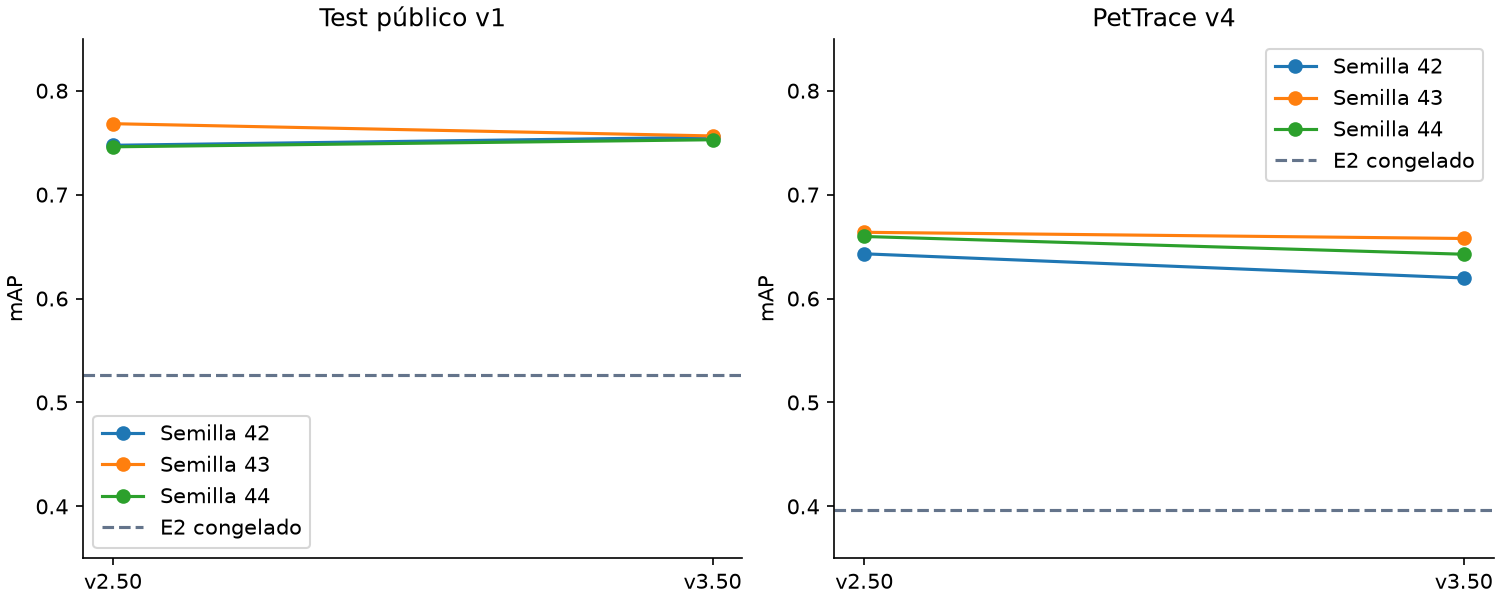

Figura reutilizada del análisis publicado: cada segmento une la misma semilla entre curaciones; E2 es el control congelado. DE describe variación entre entrenamientos, no incertidumbre poblacional.

| Base | Semilla | Modelo registrado | Evaluación pública | Evaluación PetTrace |
|---|---:|---|---|---|
| v2.50 | 42 | `pettrace-embedder/6` | [Run](https://ml.pettrace.app/#/experiments/3/runs/e87a4c7f91c74110af3d5ffe542845d9) | [Run](https://ml.pettrace.app/#/experiments/3/runs/ff087f9c8894405ca527c1a14fbcd6a4) |
| v2.50 | 43 | `pettrace-embedder/8` | [Run](https://ml.pettrace.app/#/experiments/3/runs/946d156273444973bb248ab474cd3497) | [Run](https://ml.pettrace.app/#/experiments/3/runs/30c22a529b1545faba0b8d184128ed9c) |
| v2.50 | 44 | `pettrace-embedder/10` | [Run](https://ml.pettrace.app/#/experiments/3/runs/3c48171bff1a428aa3552fdff554e2a3) | [Run](https://ml.pettrace.app/#/experiments/3/runs/373b3c8489cd4857b82cf0e40ca5d57f) |
| v3.50 | 42 | `pettrace-embedder/7` | [Run](https://ml.pettrace.app/#/experiments/3/runs/9b4f7ee0ff3b43ad9b69e791ae1ca87d) | [Run](https://ml.pettrace.app/#/experiments/3/runs/7a99528a9d9347168d19ce353a15914e) |
| v3.50 | 43 | `pettrace-embedder/9` | [Run](https://ml.pettrace.app/#/experiments/3/runs/33a7cbae740b447d83ace5d017e7bfd1) | [Run](https://ml.pettrace.app/#/experiments/3/runs/6a57fa7a6b504db6899a76706e2a0197) |
| v3.50 | 44 | `pettrace-embedder/11` | [Run](https://ml.pettrace.app/#/experiments/3/runs/eb1da70b4d8040cb8de03865d6c3fbf6) | [Run](https://ml.pettrace.app/#/experiments/3/runs/4dc917b4b9c34607bc70b7eb4205af4e) |

[Análisis y recibo de publicación](https://ml.pettrace.app/#/experiments/3/runs/de5b422b2f26462dab85e173149a486d). En PetTrace, mAP disminuye en las tres parejas (media −0,0154); en público cambia +0,0009. No se elige la mejor semilla por su test. Los modelos 6–11 son candidatos, sin promoción de alias.

Estas repeticiones se ejecutaron mediante `tools/repeat_e3.py`; se incorporan como evidencia histórica verificada y no se mezclan con la corrida comparable v4.50.


#### Recuperar resultados y modelo publicados

Con PetTrace instalado, ejecuta la celda que define `configure_private_access` y esta celda de recuperación. No necesita los datos originales ni una GPU de entrenamiento. Descarga los resultados y el modelo una vez, reutiliza su copia local y verifica recibos, hashes y golden set.

Quedan disponibles `published_results["public"]`, `published_results["private"]` y `published_model.pipeline`. Se recupera la versión original de semilla 42 indicada abajo; las repeticiones permanecen identificadas por semilla. Ejecutar todas las celdas del notebook inicia también el protocolo de una nueva corrida.


In [44]:
PUBLISHED_MODEL_VERSION = '5'
PUBLISHED_RUNS = {
    "public": {
        "run_id": "e61d1d35da6c4635913115c93a0cf3e1",
        "commit": "dd7a00cb8b3638759ffa0216251e62d334b5bf10",
        "evaluation_sha256": "7935b45e8d146f45e184abd67d387ee21f758d9df41503319d76aa62279a7847"
    },
    "private": {
        "run_id": "50770cc30ff84aadad4840e502339fe2",
        "commit": "8b12db0dce41040a821f9792bea5b352342263ce",
        "evaluation_sha256": "f4c9c04935160835e1c7a37bd74e8ff0e2a3d567d672730b3e28517e89241395"
    }
}
PUBLISHED_MODEL_HASHES = {
    "encoder.onnx": "315256de1580c9e734663e7ff616f2449862d0eb61e8d5c4d9cab3f088a35598",
    "detector.onnx": "da8f9b9ebea5157cdcefa7bea9fd782249ebdf119f917c07d64e5b41942b9c9d",
    "head.onnx": "97ec53212c4462492d345f10ac15176022b43828db4453c1ba77cf52f2500391"
}

configure_private_access(names=("MLFLOW_TRACKING_USERNAME", "MLFLOW_TRACKING_PASSWORD"))
from pettrace.experiments.e3 import load_published
published_model, published_results = load_published(
    PUBLISHED_RUNS, PUBLISHED_MODEL_HASHES, PUBLISHED_MODEL_VERSION)
print(f"Model ready: models:/pettrace-embedder/{PUBLISHED_MODEL_VERSION}; results loaded, no new run.")


pettrace-training@v1
group    queries gallery  Rank-1  Rank-5 Rank-10     mAP
global       277      34   81.2%   98.6%   98.9%   0.755
cat          162      34   75.9%   97.5%   98.1%   0.666
dog          115      26   88.7%  100.0%  100.0%   0.881
EER on all pairs (optimistic) 13.7% at threshold 0.847 → FAR 13.7%, FRR 13.7% 



pettrace-reid@v4
group    queries gallery  Rank-1  Rank-5 Rank-10     mAP
global       305      16   73.8%   99.3%   99.7%   0.620
cat          156      15   73.7%  100.0%  100.0%   0.655
dog          149      16   73.8%   98.7%   99.3%   0.583
EER on all pairs (optimistic) 14.8% at threshold 0.863 → FAR 14.8%, FRR 14.8% 



Model ready: models:/pettrace-embedder/5; results loaded, no new run.


| Dataset | Grupo | Consultas | Galería (identidades) | Rank-1 | Rank-2 | mAP |
|---|---|---:|---:|---:|---:|---:|
| Público v1 · test | global | 277 | 34 | 82.67% | 92.06% | 0.7635 |
| Público v1 · test | cat | 162 | 34 | 76.54% | 90.12% | 0.6831 |
| Público v1 · test | dog | 115 | 26 | 91.30% | 94.78% | 0.8768 |
| PetTrace v4 | global | 305 | 16 | 77.05% | 91.80% | 0.6695 |
| PetTrace v4 | cat | 156 | 15 | 76.92% | 89.74% | 0.6818 |
| PetTrace v4 | dog | 149 | 16 | 77.18% | 93.96% | 0.6565 |

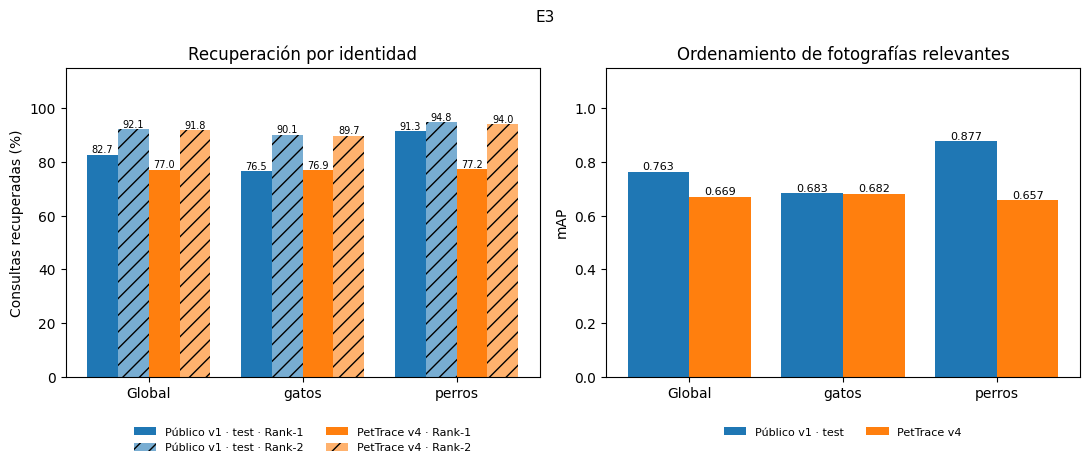

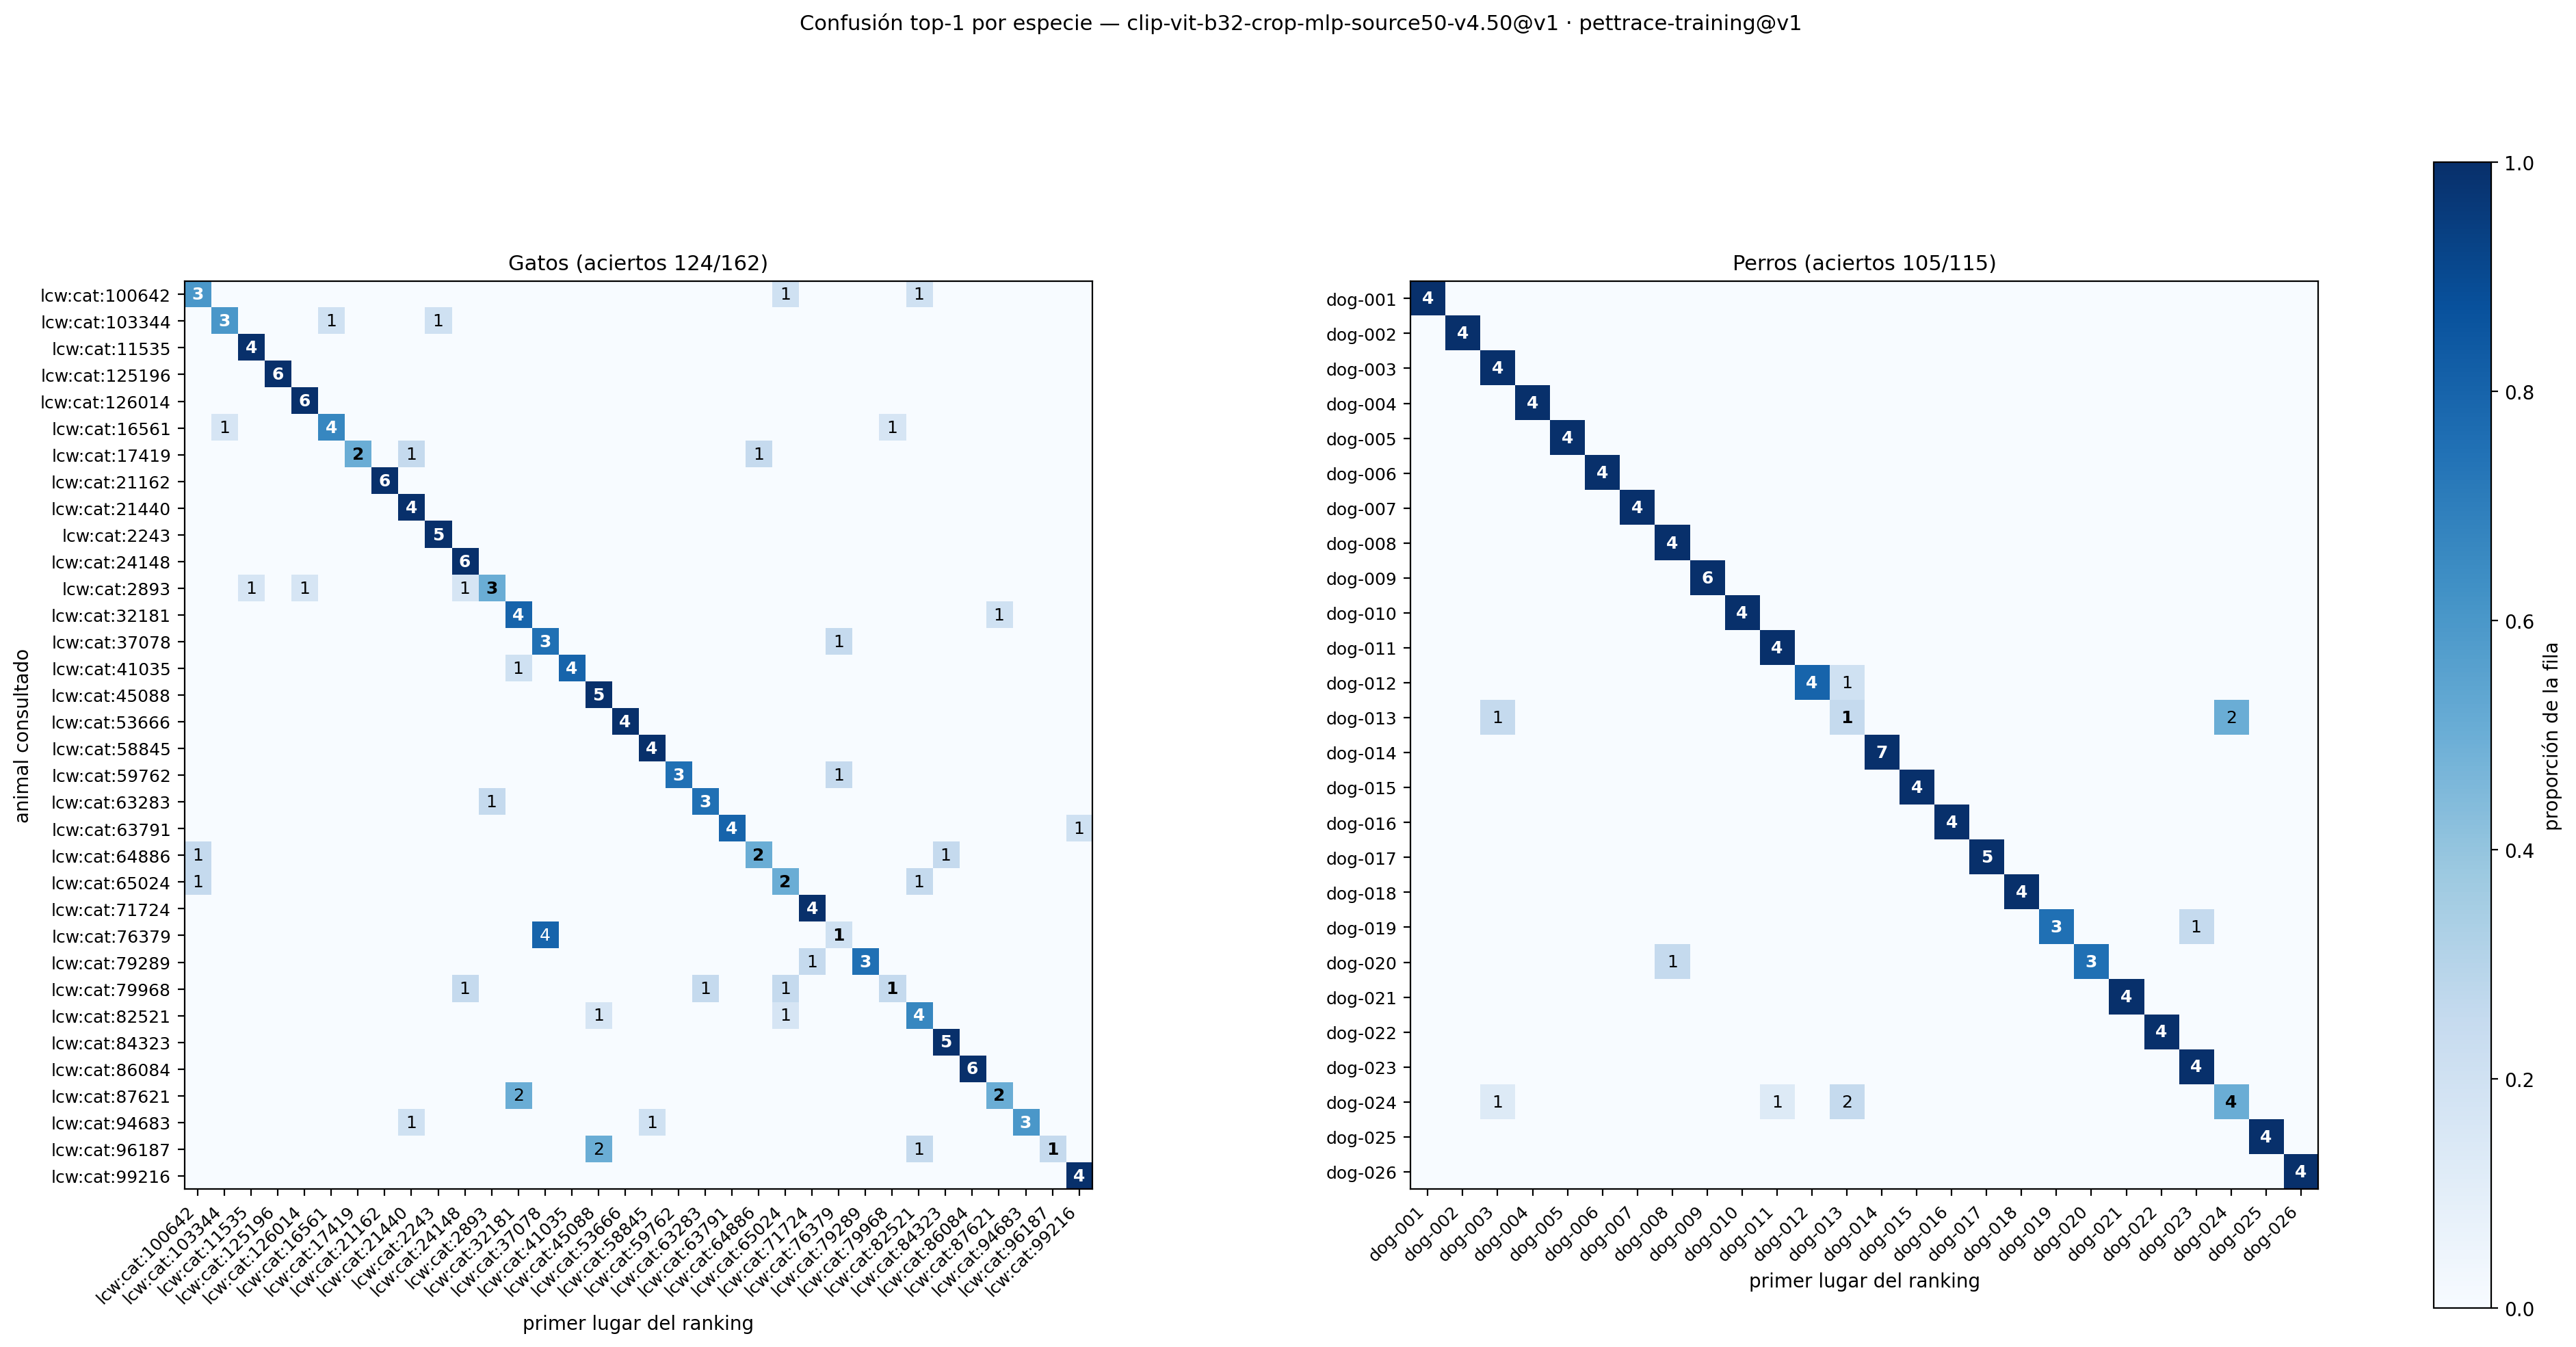

Confusión top-1 del test público reservado, por identidad y especie.

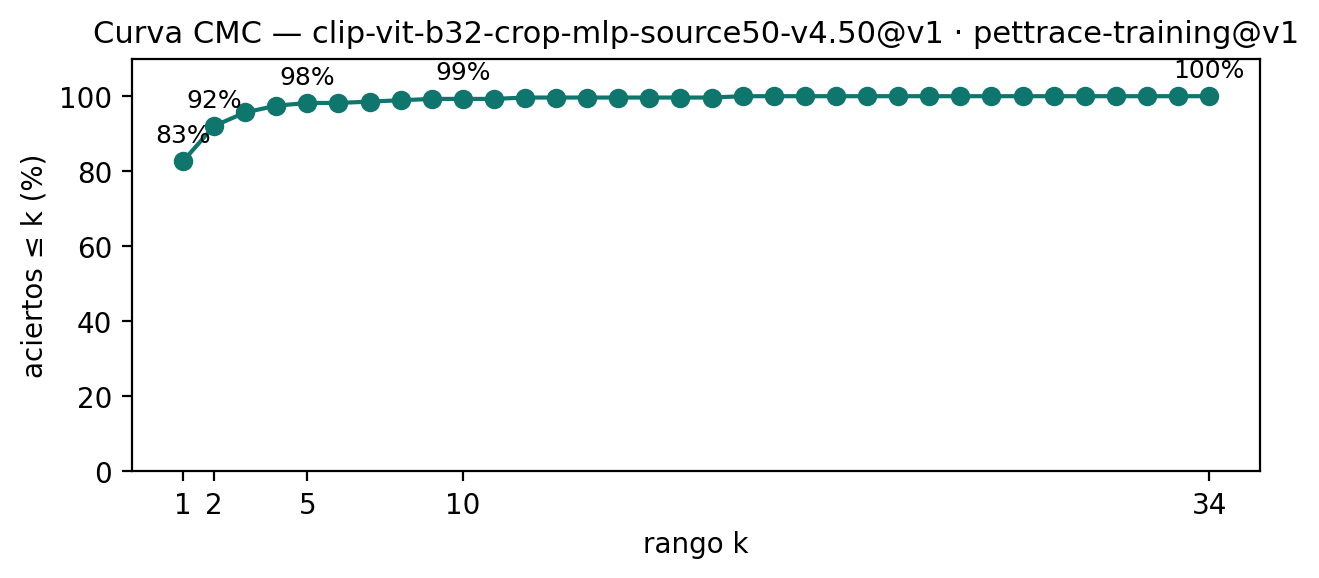

CMC del test público: incluye Rank-1, Rank-2 y otros rangos.

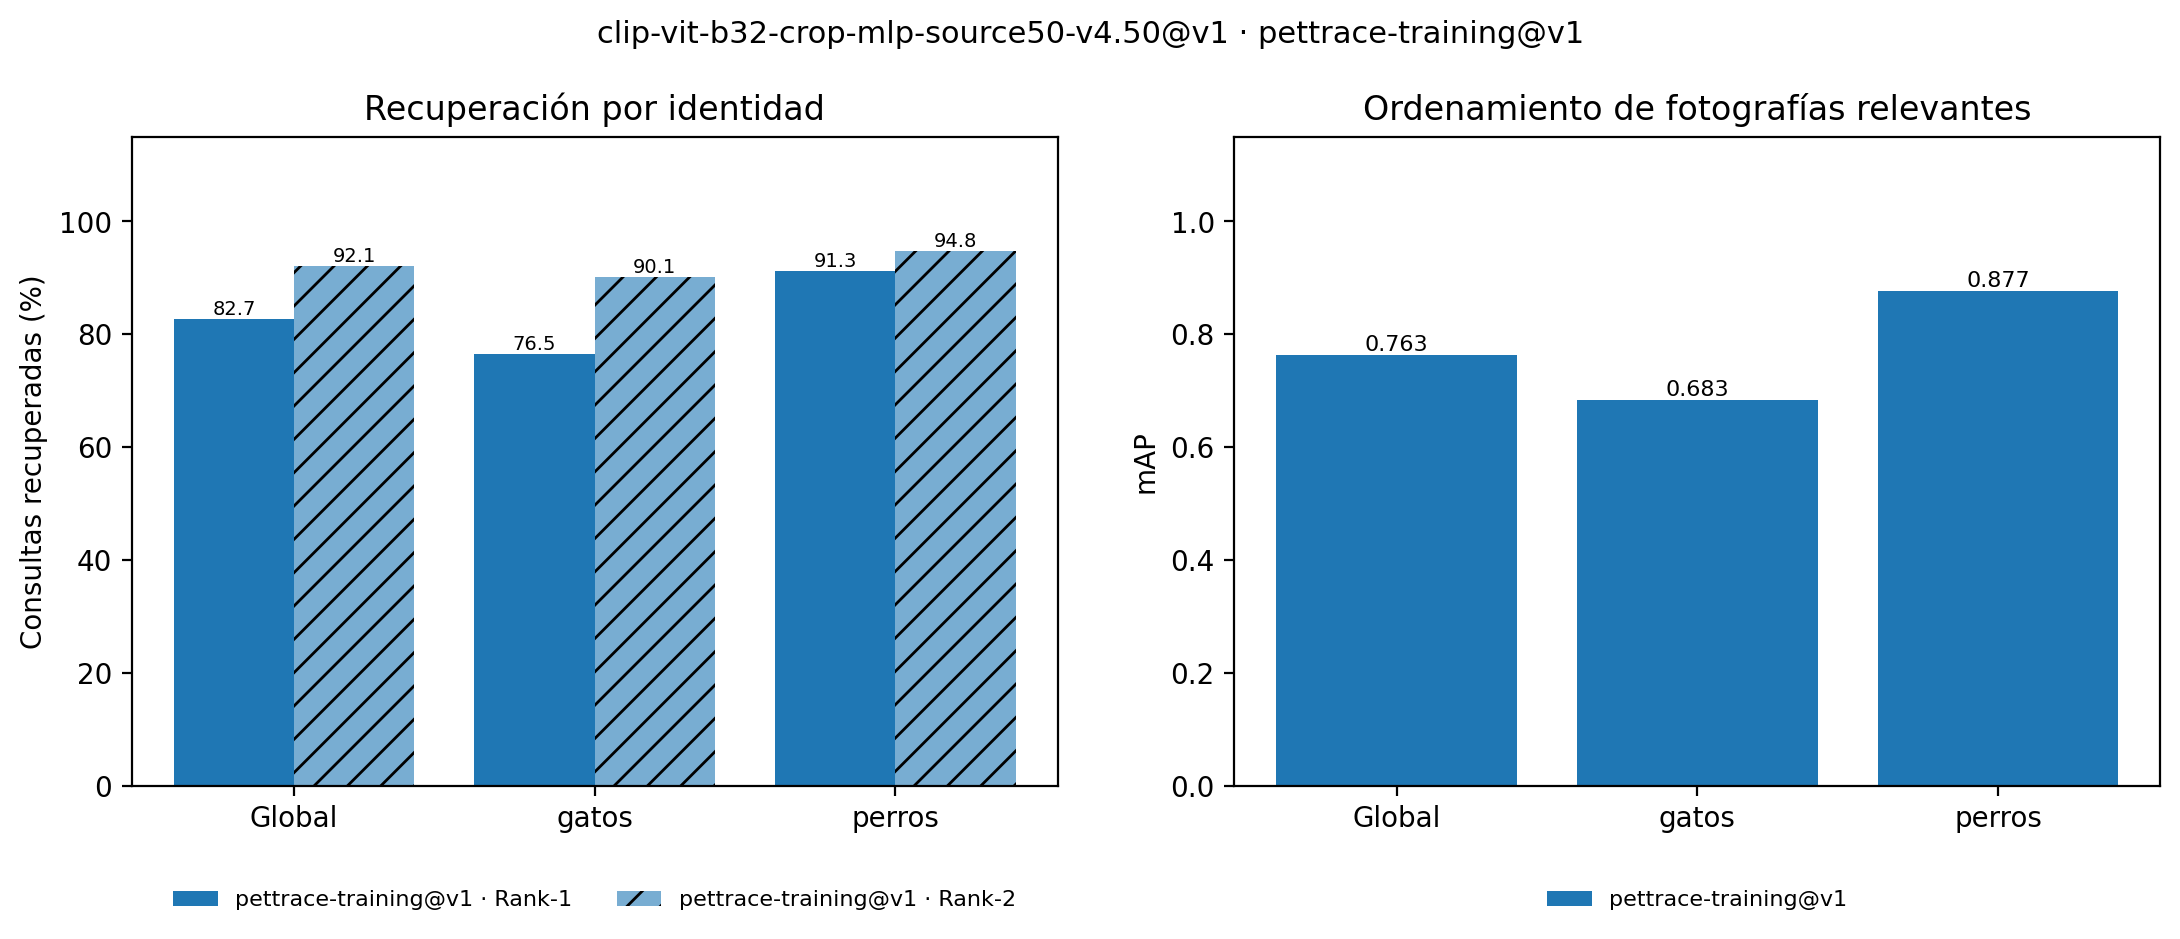

Rank-1/Rank-2 y mAP públicos, globales y por especie.

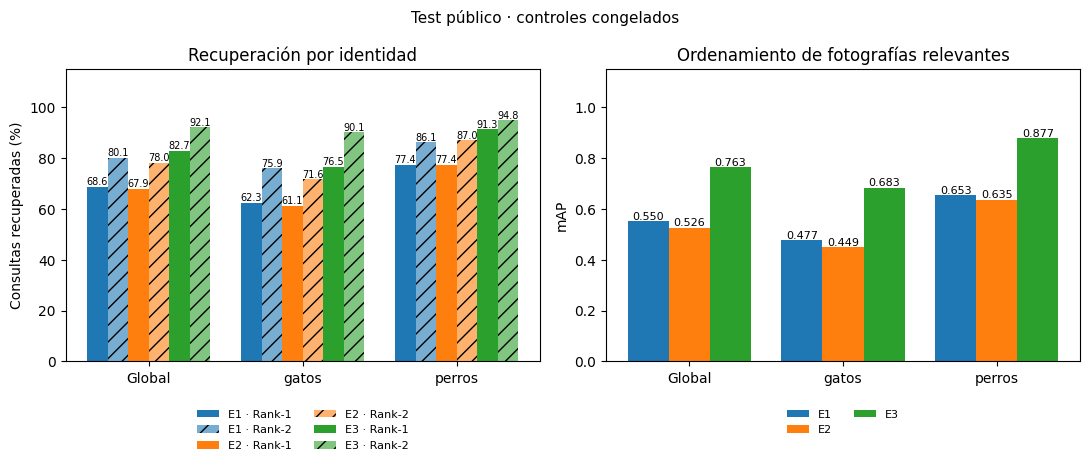

E3 menos cada control publicado: {'E1': {'rank1': 0.1407942238267148, 'rank5': 0.09386281588447654, 'mAP': 0.2134169366395593}, 'E2': {'rank1': 0.148014440433213, 'rank5': 0.10108303249097472, 'mAP': 0.2372815345332464}}


In [45]:
from pettrace.evaluation.research import save_benchmark_comparison

public_ev = evaluate(public_ds, e3_model.pipeline, zero_shot=True)
public_summary = save(public_ev, e3_model, str(PUBLIC_REPORT))
save_provenance(PUBLIC_REPORT, e3_model)
comparison_markdown, comparison_figure = save_benchmark_comparison(public_ev, ev, REPORT, EXPERIMENT)
display(Markdown(comparison_markdown))
display(comparison_figure)
import matplotlib.pyplot as plt
plt.close(comparison_figure)
for filename, caption in (("confusion.png", "Confusión top-1 del test público reservado, por identidad y especie."),
                          ("cmc.png", "CMC del test público: incluye Rank-1, Rank-2 y otros rangos."),
                          ("rank1_rank2_map.png", "Rank-1/Rank-2 y mAP públicos, globales y por especie.")):
    display(Image(str(PUBLIC_REPORT / filename), width=900))
    display(Markdown(caption))

from pettrace.experiments.e3 import frozen_controls
from pettrace.evaluation.figures import comparison_figure as plot_comparison
public_controls, public_control_summaries = frozen_controls(public_ev, "public", PUBLIC_REPORT)
fig = plot_comparison({**public_controls, "E3": public_ev}, "Test público · controles congelados")
fig.savefig(PUBLIC_REPORT / "frozen-comparison.png", dpi=160, bbox_inches="tight")
display(fig)
plt.close(fig)
public_deltas = {label: {key: public_summary["global"][key]-summary["global"][key]
                       for key in ("rank1", "rank5", "mAP")} for label, summary in public_control_summaries.items()}
(PUBLIC_REPORT / "comparison.json").write_text(json.dumps(public_deltas, indent=2))
print("E3 menos cada control publicado:", public_deltas)


In [46]:
from pettrace.experiments.e3 import frozen_controls
s3 = save(ev, e3_model, str(REPORT))
baseline_evaluations, baseline_summaries = frozen_controls(ev, "private", REPORT)
summaries = {**baseline_summaries, "E3": s3}
lines = ["| Model | Scope | Queries | Rank-1 | Rank-5 | Rank-10 | mAP |", "|---|---|---:|---:|---:|---:|---:|"]
for label, summary in summaries.items():
    for scope in ("global", "cat", "dog"):
        values = summary["global"] if scope == "global" else summary["per_species"][scope]
        lines.append(f"| {label} | {scope} | {values['queries']} | {values['rank1']:.2%} | {values['rank5']:.2%} | {values['rank10']:.2%} | {values['mAP']:.4f} |")
display(Markdown("\n".join(lines)))
eer_lines = ["| Model | Descriptive EER | Threshold fitted on these pairs |", "|---|---:|---:|"]
for label, summary in summaries.items():
    eer_lines.append(f"| {label} | {summary['eer']:.2%} | {summary['threshold']:.4f} |")
display(Markdown("\n".join(eer_lines)))
comparison = {label: {key: s3["global"][key] - summary["global"][key]
                     for key in ("rank1", "rank5", "mAP")} for label, summary in baseline_summaries.items()}
(REPORT / "comparison.json").write_text(json.dumps(comparison, indent=2))


| Model | Scope | Queries | Rank-1 | Rank-5 | Rank-10 | mAP |
|---|---|---:|---:|---:|---:|---:|
| E1 | global | 305 | 65.90% | 94.10% | 98.69% | 0.3751 |
| E1 | cat | 156 | 67.95% | 94.87% | 98.72% | 0.4027 |
| E1 | dog | 149 | 63.76% | 93.29% | 98.66% | 0.3463 |
| E2 | global | 305 | 67.87% | 92.13% | 98.69% | 0.3960 |
| E2 | cat | 156 | 67.31% | 93.59% | 98.08% | 0.3950 |
| E2 | dog | 149 | 68.46% | 90.60% | 99.33% | 0.3971 |
| E3 | global | 305 | 77.05% | 99.34% | 100.00% | 0.6695 |
| E3 | cat | 156 | 76.92% | 100.00% | 100.00% | 0.6818 |
| E3 | dog | 149 | 77.18% | 98.66% | 100.00% | 0.6565 |

| Model | Descriptive EER | Threshold fitted on these pairs |
|---|---:|---:|
| E1 | 36.23% | 0.7970 |
| E2 | 33.83% | 0.8154 |
| E3 | 14.01% | 0.7664 |

228

#### 3.2.1 Variación por identidad

El promedio global pondera por consultas. La tabla siguiente contrasta las mismas fotografías para cada individuo, conserva su especie y presenta Rank-1/mAP de las tres condiciones. El promedio macro por identidad asigna el mismo peso a cada animal; permite examinar si el resultado global está dominado por mascotas con más fotos. Este análisis describe heterogeneidad y no identifica causas del error.


In [47]:
# Reuse the same per-query outputs, without additional model inference.
per_model = {label: evaluation.result["test"]["per_query"]
             for label, evaluation in {**baseline_evaluations, "E3": ev}.items()}
identity_findings = []
identity_lines = ["| Identidad | Especie | Consultas | Rank-1 E1 | Rank-1 E2 | Rank-1 E3 | mAP E3 | Δ R1 E3−E2 (pp) |",
                  "|---|---|---:|---:|---:|---:|---:|---:|"]
for animal in sorted({row["animal"] for row in per_model["E3"]}):
    selected = {label: [row for row in rows if row["animal"] == animal]
                for label, rows in per_model.items()}
    values = {label: {"rank1": float(np.mean([row["rank"] == 1 for row in rows])),
                      "mAP": float(np.mean([row["ap"] for row in rows]))}
              for label, rows in selected.items()}
    finding = {"animal": animal, "species": ds.animals[animal]["species"],
               "queries": len(selected["E3"]), "models": values,
               "rank1_delta_e3_e2": values["E3"]["rank1"] - values["E2"]["rank1"]}
    identity_findings.append(finding)
    identity_lines.append(f"| `{animal}` | {finding['species']} | {finding['queries']} | "
                          f"{values['E1']['rank1']:.1%} | {values['E2']['rank1']:.1%} | "
                          f"{values['E3']['rank1']:.1%} | {values['E3']['mAP']:.4f} | "
                          f"{finding['rank1_delta_e3_e2']*100:+.2f} |")
display(Markdown("\n".join(identity_lines)))
macro_rank1 = {label: float(np.mean([row["models"][label]["rank1"] for row in identity_findings]))
               for label in per_model}
print("Rank-1 macro por identidad:", macro_rank1)
analysis = {"dataset": ds.name, "dataset_commit": ds.commit, "dataset_fingerprint": ds.fingerprint,
            "protocol": PROTOCOL, "per_animal": identity_findings, "macro_rank1": macro_rank1,
            "comparison": comparison, "training": train_summary,
            "training_dataset_fingerprint": prepared.fingerprint, "coverage": coverage_metrics}
(REPORT / "analysis.json").write_text(json.dumps(analysis, indent=2))


| Identidad | Especie | Consultas | Rank-1 E1 | Rank-1 E2 | Rank-1 E3 | mAP E3 | Δ R1 E3−E2 (pp) |
|---|---|---:|---:|---:|---:|---:|---:|
| `cat-01` | cat | 10 | 30.0% | 30.0% | 30.0% | 0.2985 | +0.00 |
| `cat-02` | cat | 10 | 50.0% | 40.0% | 20.0% | 0.3550 | -20.00 |
| `cat-03` | cat | 10 | 100.0% | 80.0% | 90.0% | 0.7947 | +10.00 |
| `cat-04` | cat | 10 | 40.0% | 40.0% | 60.0% | 0.5694 | +20.00 |
| `cat-05` | cat | 8 | 87.5% | 87.5% | 100.0% | 0.9978 | +12.50 |
| `cat-06` | cat | 8 | 100.0% | 100.0% | 87.5% | 0.7844 | -12.50 |
| `cat-07` | cat | 7 | 57.1% | 57.1% | 57.1% | 0.4456 | +0.00 |
| `cat-08` | cat | 10 | 40.0% | 80.0% | 30.0% | 0.2472 | -50.00 |
| `cat-09` | cat | 10 | 40.0% | 60.0% | 90.0% | 0.7461 | +30.00 |
| `cat-10` | cat | 10 | 80.0% | 50.0% | 100.0% | 0.7574 | +50.00 |
| `cat-11` | cat | 8 | 75.0% | 100.0% | 100.0% | 0.7741 | +0.00 |
| `cat-12` | cat | 18 | 88.9% | 94.4% | 94.4% | 0.7556 | +0.00 |
| `cat-13` | cat | 14 | 71.4% | 64.3% | 92.9% | 0.9059 | +28.57 |
| `cat-14` | cat | 15 | 80.0% | 66.7% | 100.0% | 0.9481 | +33.33 |
| `cat-15` | cat | 8 | 62.5% | 50.0% | 75.0% | 0.5762 | +25.00 |
| `dog-01` | dog | 10 | 70.0% | 50.0% | 80.0% | 0.6143 | +30.00 |
| `dog-02` | dog | 14 | 71.4% | 64.3% | 92.9% | 0.7338 | +28.57 |
| `dog-03` | dog | 10 | 40.0% | 40.0% | 50.0% | 0.5538 | +10.00 |
| `dog-04` | dog | 10 | 30.0% | 60.0% | 70.0% | 0.6076 | +10.00 |
| `dog-05` | dog | 9 | 88.9% | 88.9% | 66.7% | 0.6906 | -22.22 |
| `dog-06` | dog | 10 | 50.0% | 50.0% | 80.0% | 0.7221 | +30.00 |
| `dog-07` | dog | 6 | 66.7% | 66.7% | 66.7% | 0.3027 | +0.00 |
| `dog-08` | dog | 11 | 54.5% | 72.7% | 90.9% | 0.5467 | +18.18 |
| `dog-09` | dog | 5 | 40.0% | 60.0% | 80.0% | 0.3829 | +20.00 |
| `dog-10` | dog | 6 | 16.7% | 50.0% | 50.0% | 0.4187 | +0.00 |
| `dog-11` | dog | 11 | 54.5% | 63.6% | 90.9% | 0.8907 | +27.27 |
| `dog-12` | dog | 8 | 100.0% | 100.0% | 100.0% | 0.9591 | +0.00 |
| `dog-13` | dog | 6 | 100.0% | 100.0% | 100.0% | 0.9617 | +0.00 |
| `dog-14` | dog | 12 | 75.0% | 83.3% | 75.0% | 0.7581 | -8.33 |
| `dog-15` | dog | 10 | 100.0% | 100.0% | 80.0% | 0.7568 | -20.00 |
| `dog-16` | dog | 11 | 54.5% | 54.5% | 54.5% | 0.3813 | +0.00 |

Rank-1 macro por identidad: {'E1': 0.6499185402411208, 'E2': 0.6787494763301215, 'E3': 0.7595156635479218}


26231

### 3.3 Discusión y limitaciones

La corrida comparable v4.50 supera a v4.20 en ambos dominios. Del 20% al 50%, Rank-1 aumenta **12,27 puntos** y mAP **0,1132** en público; en PetTrace aumenta **5,57 puntos** y **0,0893**, respectivamente. Esto es consistente con un beneficio del volumen, pero una sola semilla por variante no establece causalidad ni incertidumbre.

La selección usa exclusivamente validación pública. La nueva base v3.50 cambia la curación respecto a v2.50: esa comparación no aísla el efecto del volumen ni demuestra que la revisión cause una mejora.

**Validez interna.** Las etiquetas públicas proceden de los publicadores y mantienen revisión exploratoria; deduplicación y filtro YOLO no verifican cada individuo ni detectan todos los animales presentes. El control de solapamiento público/privado utiliza hashes exactos y no descarta todas las copias transformadas. La corrida interactiva usa una semilla; las tres repeticiones publicadas en la sección 3.2 permiten describir variación del entrenamiento, no incertidumbre poblacional.

**Validez externa.** v4 incluye 31 mascotas y ya fue observado en E1/E2. La evaluación no separa sesiones ni demuestra transferencia a nuevos entornos de captura. El porcentaje de fuente usado mide fotos antes de limpieza; no implica que el resto sea elegible ni que aumentar el volumen produzca una mejora proporcional.

**Validez de la medición.** El ranking se condiciona a la especie anotada y a una identidad presente en la galería. Rank-k se promedia por consultas, no por animales; mAP ordena fotos. La EER se ajusta sobre los mismos pares reportados y no valida un umbral de despliegue.

La siguiente fase deberá contrastar más identidades y sesiones, completar la serie de volumen con limpieza común y estimar incertidumbre por identidad, manteniendo un benchmark adicional independiente para cualquier selección posterior de modelos o hiperparámetros.


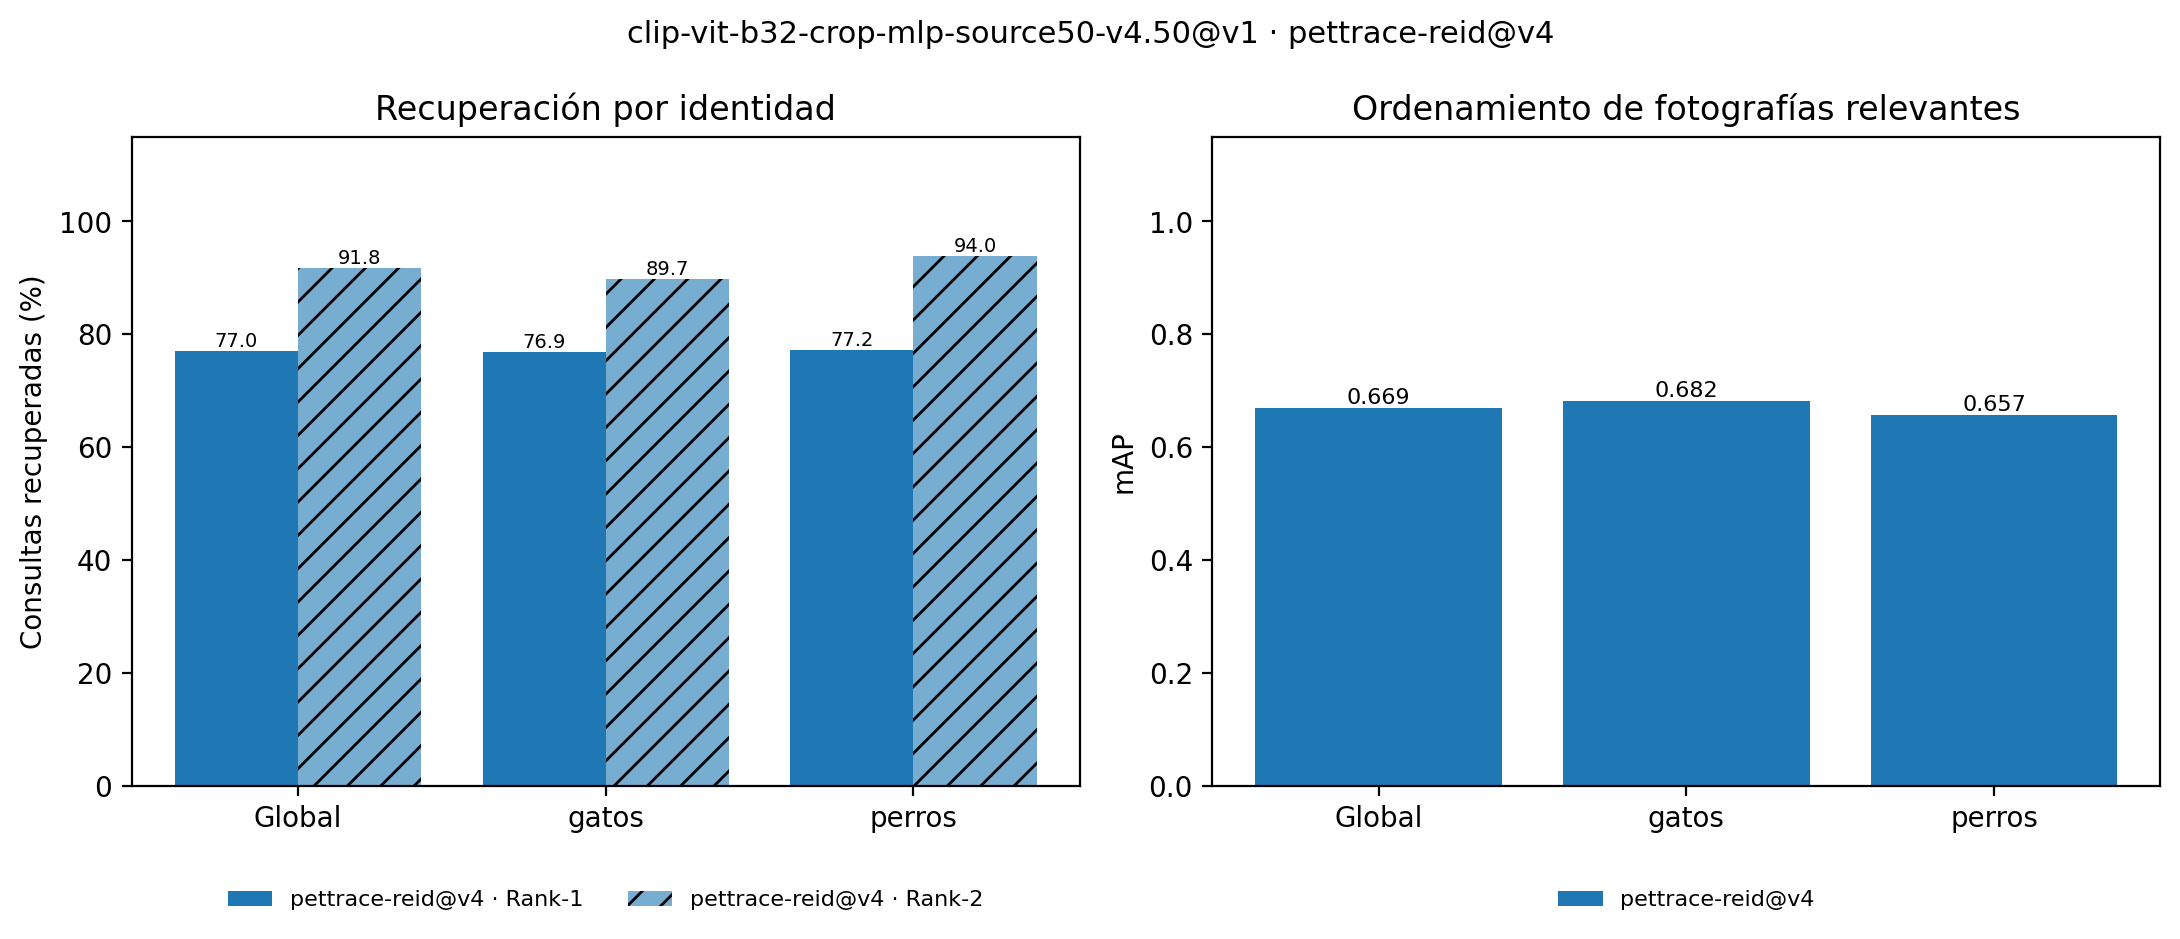

Rank-1/Rank-2 por identidad y mAP por fotografía, desglosados por especie; gráficos calculados con los resultados de esta investigación.

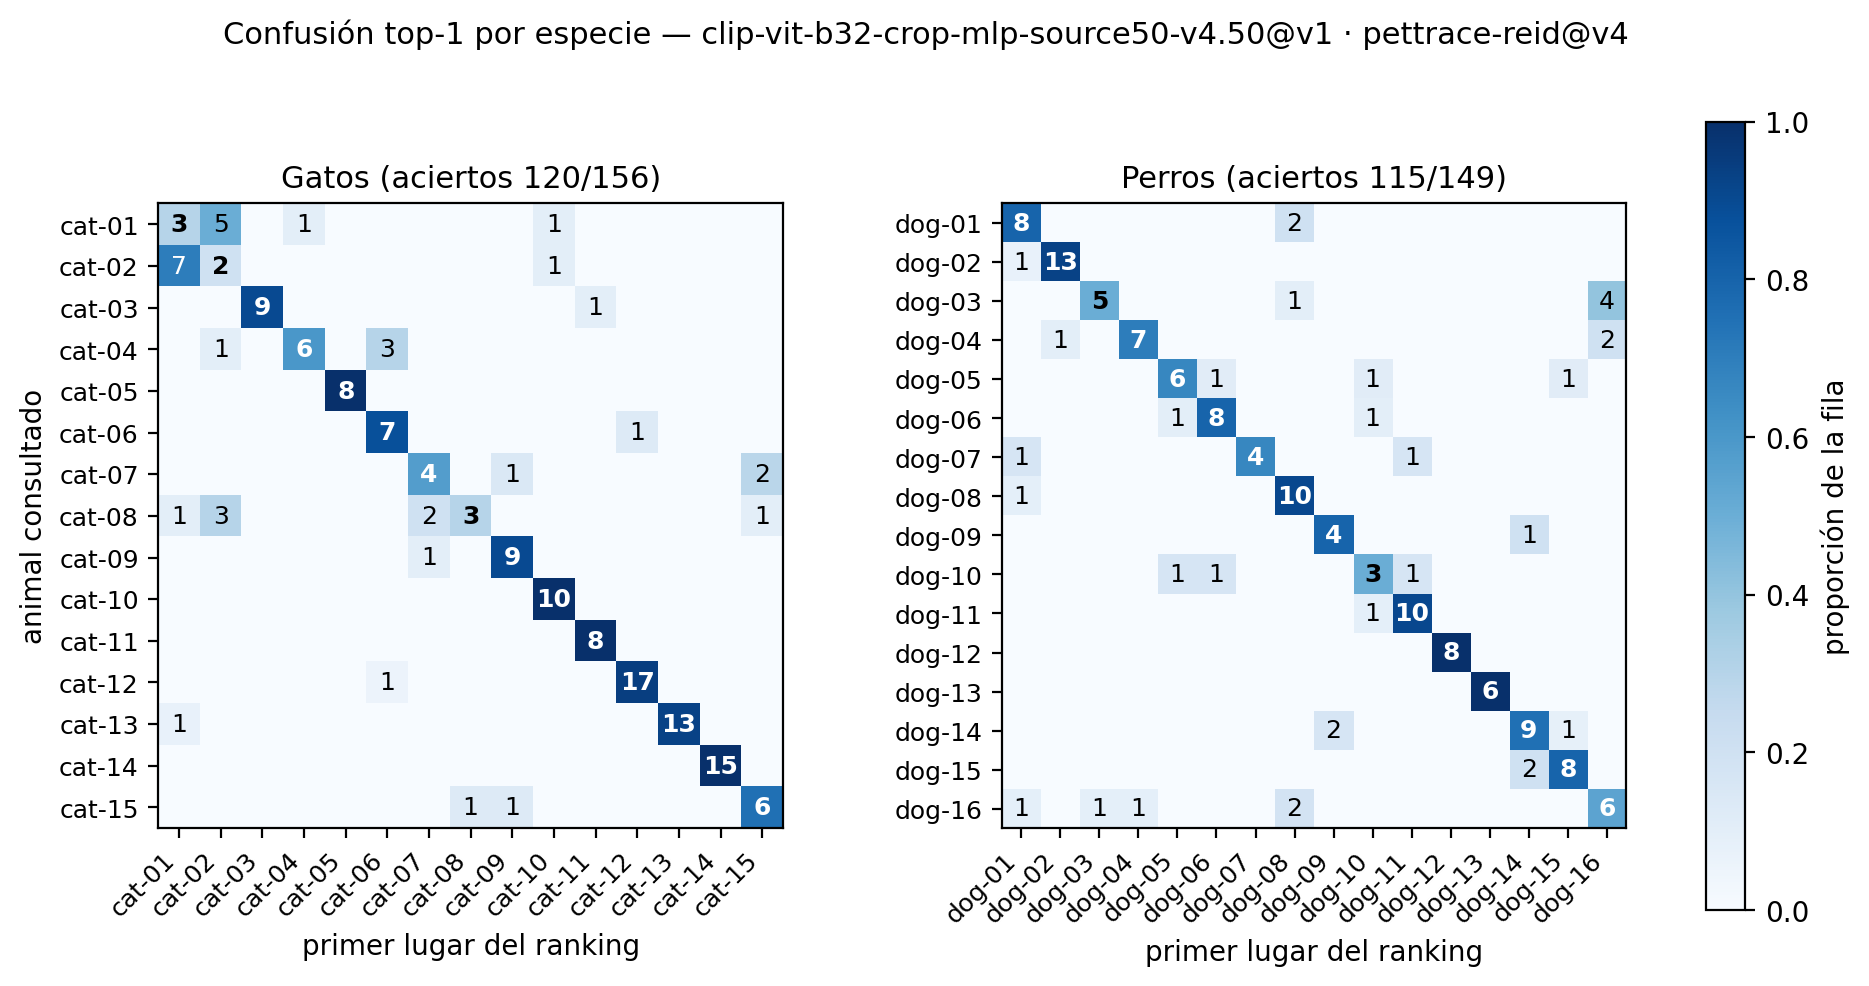

Filas: identidad real; columnas: primera identidad recuperada. Las confusiones localizan casos, sin explicar su causa.

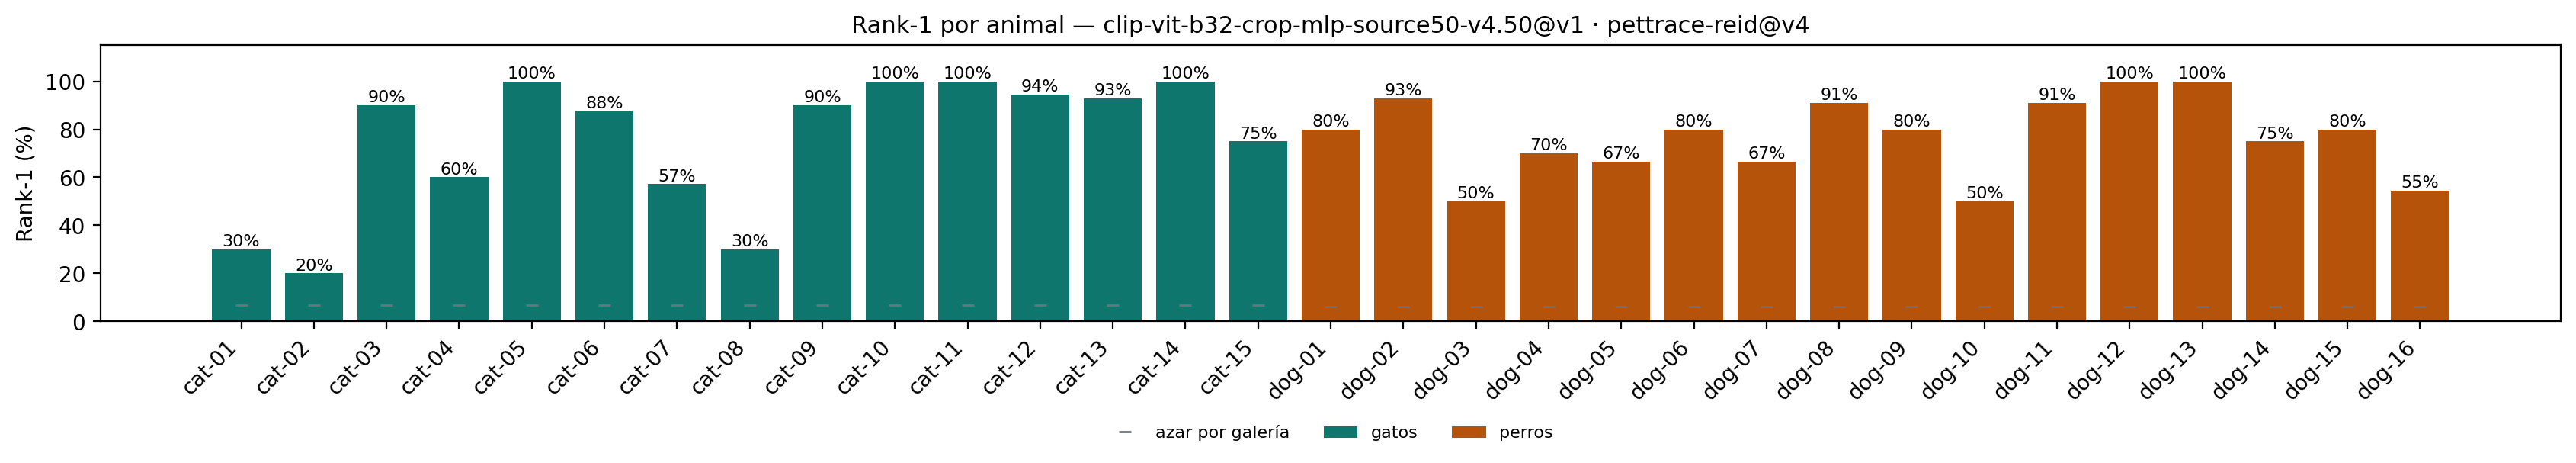

Rank-1 por identidad: muestra cómo se distribuyen los aciertos entre mascotas.

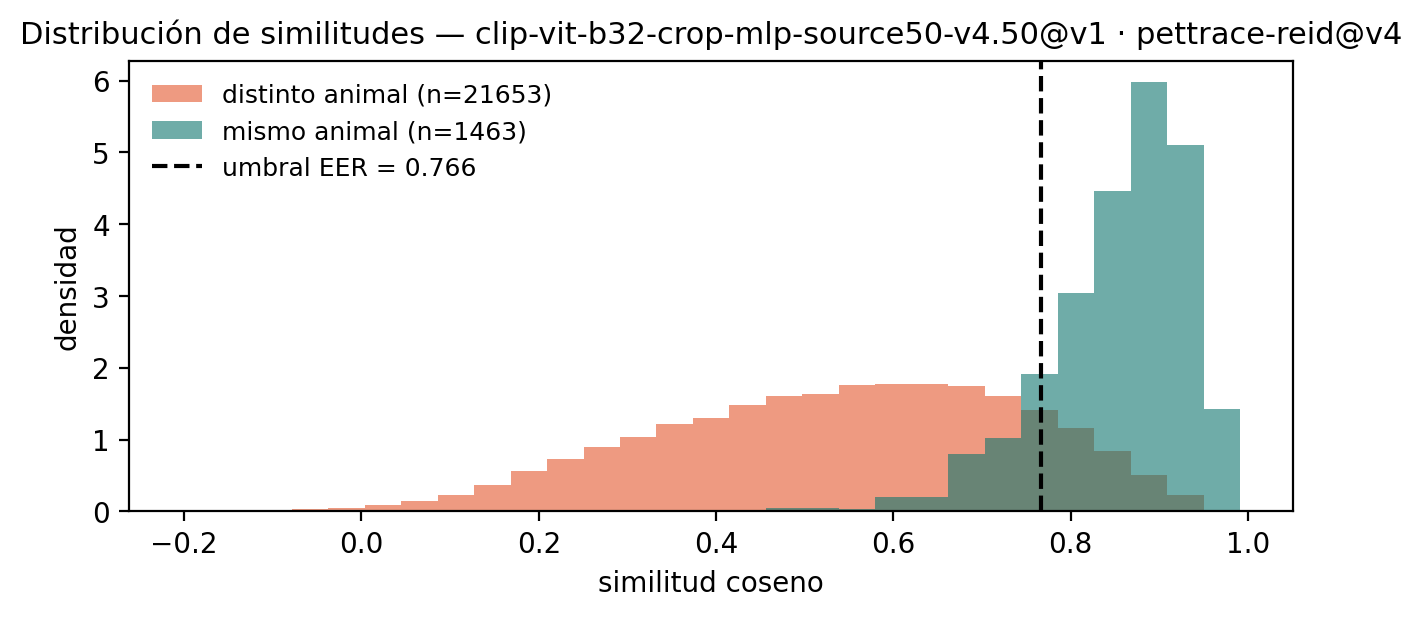

Scores positivos y negativos. La EER y su umbral se estiman sobre estos mismos pares; no son calibración independiente.

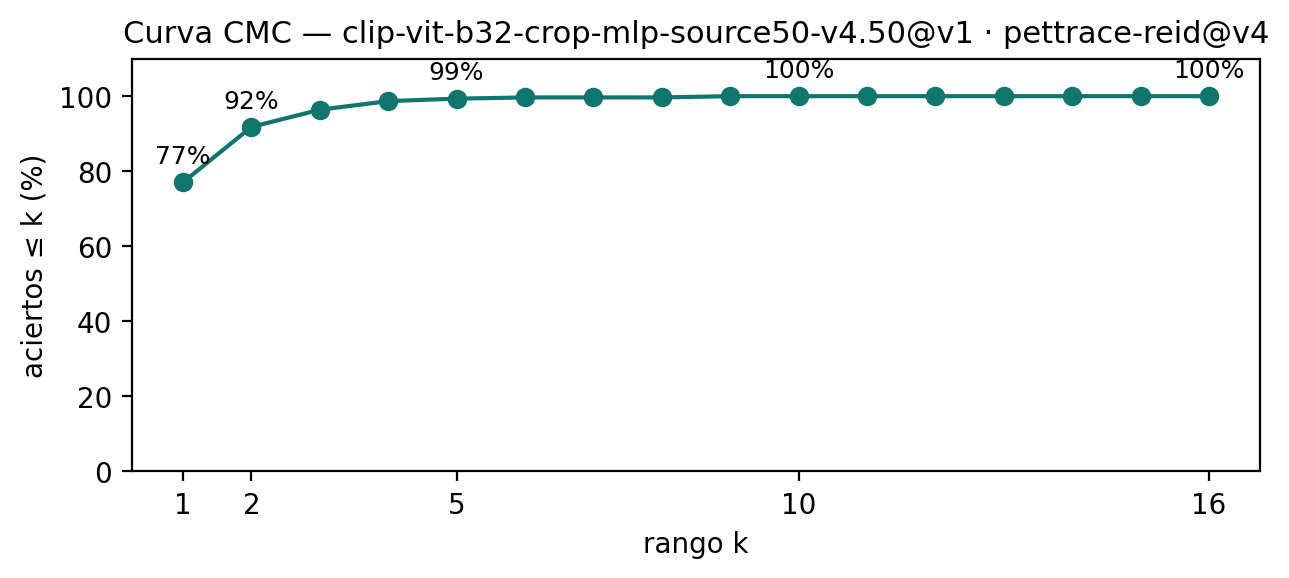

CMC: fracción de consultas cuya identidad correcta aparece entre los primeros k candidatos.

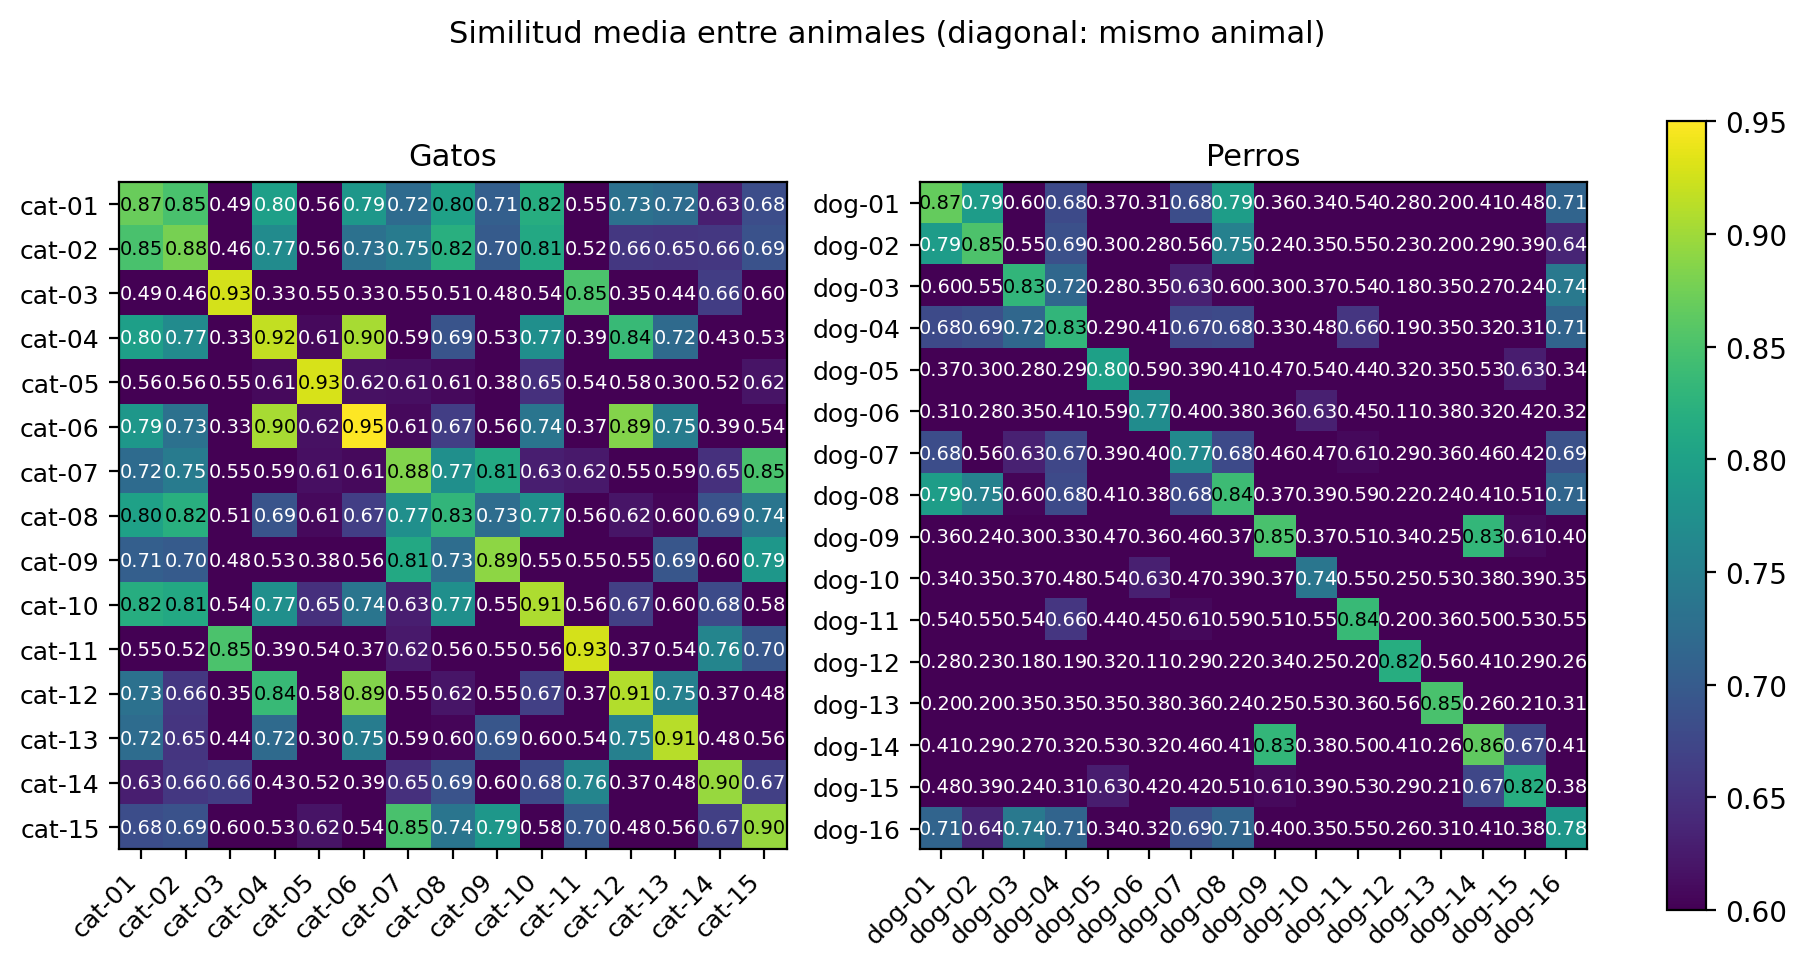

Similitud entre embeddings; las agrupaciones deben interpretarse junto a etiquetas y confusiones.

# E3 · Hallazgos de la ejecución

Dataset: pettrace-reid@v4; commit: 8b12db0dce41040a821f9792bea5b352342263ce.
Muestra solicitada: 50% de cada fuente; adquiridas: 347,296 fotos.
Train efectivo: 26,955 fotos, 6,361 identidades; 3.8807% de las fuentes.
Checkpoint: época 23, mAP macro público 0.7829.

- E3 − E1: Rank-1 +11.15 pp; Rank-5 +5.25 pp; mAP +0.2943.
- E3 − E2: Rank-1 +9.18 pp; Rank-5 +7.21 pp; mAP +0.2734.
- Test público E3 − E1: Rank-1 +14.08 pp; mAP +0.2134.
- Test público E3 − E2: Rank-1 +14.80 pp; mAP +0.2373.

Contraste descriptivo; no establece significancia, efecto causal del fondo, ni independencia entre sesiones.

In [48]:
captions = {
    "rank1_rank2_map": "Rank-1/Rank-2 por identidad y mAP por fotografía, desglosados por especie; gráficos calculados con los resultados de esta investigación.",
    "confusion": "Filas: identidad real; columnas: primera identidad recuperada. Las confusiones localizan casos, sin explicar su causa.",
    "rank1_por_animal": "Rank-1 por identidad: muestra cómo se distribuyen los aciertos entre mascotas.",
    "distribucion_scores": "Scores positivos y negativos. La EER y su umbral se estiman sobre estos mismos pares; no son calibración independiente.",
    "cmc": "CMC: fracción de consultas cuya identidad correcta aparece entre los primeros k candidatos.",
    "matriz_similitud": "Similitud entre embeddings; las agrupaciones deben interpretarse junto a etiquetas y confusiones.",
}
for name, caption in captions.items():
    image_path = REPORT / f"{name}.png"
    if image_path.exists():
        display(Image(str(image_path), width=760))
        display(Markdown(caption))
findings = ["# E3 · Hallazgos de la ejecución", "",
            f"Dataset: {ds.name}; commit: {ds.commit}.",
            f"Muestra solicitada: {SOURCE_SAMPLE_PCT}% de cada fuente; adquiridas: {coverage_metrics['dataset.sampled_photos']:,} fotos.",
            f"Train efectivo: {coverage_metrics['dataset.train_photos']:,} fotos, {coverage_metrics['dataset.train_identities']:,} identidades; {coverage_metrics['dataset.train_pct']:.4f}% de las fuentes.",
            f"Checkpoint: época {train_summary['best_epoch']}, mAP macro público {train_summary['best_val_mAP']:.4f}.", ""]
for label, delta in comparison.items():
    findings.append(f"- E3 − {label}: Rank-1 {delta['rank1']*100:+.2f} pp; Rank-5 {delta['rank5']*100:+.2f} pp; mAP {delta['mAP']:+.4f}.")
for label, delta in public_deltas.items():
    findings.append(f"- Test público E3 − {label}: Rank-1 {delta['rank1']*100:+.2f} pp; mAP {delta['mAP']:+.4f}.")
findings.extend(["", "Contraste descriptivo; no establece significancia, efecto causal del fondo, ni independencia entre sesiones."])
findings_text = "\n".join(findings)
(REPORT / "findings.md").write_text(findings_text)
display(Markdown(findings_text))


### 3.4 Trazabilidad y publicación

Los artefactos se conservan localmente bajo un directorio nuevo por corrida: configuración, procedencia de fuentes, revisión, manifiesto, auditoría, historia/checkpoint, curvas, modelo ONNX, líneas base y resultados. El recibo `publication.json` indica si el resultado se publicó.

Cada corrida publica sus resultados en MLflow. `LOG_TO_MLFLOW = True` hace visible esa política; el helper no ofrece una vía para omitirla. `REGISTER_E3` controla por separado el registro de una versión del modelo. La publicación utiliza el experimento existente sin promover un alias.

Las hojas de contacto permanecen en el piloto local. No se copian al reporte ni se publican fotos; el manifiesto de evidencia conserva identificadores/rutas y hashes, no los campos personales de las fuentes.

#### 3.4.1 Evidencia de la corrida

Ambos dominios conservan el mismo diseño, configuración y volumen de entrenamiento.


In [49]:
# The package writes the shared design and evidence during the publication step below.


#### 3.4.2 Métricas de entrenamiento

Preparar la historia por época y los parámetros que acompañarán a los dos runs.


In [50]:
# Epoch metrics and dataset coverage are published by the same package helper.


#### 3.4.3 Publicar los dos dominios

Publicar test público y PetTrace por separado, añadir métricas de entrenamiento y subir sus recibos. Si falla la conexión, reejecutar esta celda; no es necesario reentrenar.


In [51]:
from pettrace.experiments.e3 import publish_results
with report_backup:
    publication = publish_results(
        public_ev, ev, e3_model, REPORT, PUBLIC_REPORT, SOURCE_SHA256,
        experiment=EXPERIMENT, source_sample_pct=SOURCE_SAMPLE_PCT, config=config,
        training_summary=train_summary, prepared_fingerprint=prepared.fingerprint,
        training_source=training_source, coverage_metrics=coverage_metrics,
        coverage_params=coverage_params, private_dataset_version=DATASET)
run_id, public_run_id = publication["run_id"], publication["public_run_id"]
print("MLflow private run:", run_id, "| Public test run:", public_run_id)


🏃 View run E3 · clip-vit-b32-crop-mlp-source50-v4.50@v1 on pettrace-training@v1 at: https://ml.pettrace.app/#/experiments/3/runs/505f6172d1bc4bb485f995e274232293
🧪 View experiment at: https://ml.pettrace.app/#/experiments/3
🏃 View run E3 · clip-vit-b32-crop-mlp-source50-v4.50@v1 on pettrace-reid@v4 at: https://ml.pettrace.app/#/experiments/3/runs/c9e6c7d5f6ac46a8bbc62733a7004982
🧪 View experiment at: https://ml.pettrace.app/#/experiments/3
Drive: respaldo confirmado (55 archivos, 01793821599348619467-f3395b2d4fc245be8ae5ac834119c05e.tar).
MLflow private run: c9e6c7d5f6ac46a8bbc62733a7004982 | Public test run: 505f6172d1bc4bb485f995e274232293


#### 3.4.4 Registrar el modelo candidato

`REGISTER_E3` conserva la opción elegida. Se reutiliza la versión si ya existe para este run; no se promueve ningún alias de servicio.


In [52]:
from pettrace.experiments.e3 import register_candidate
if REGISTER_E3:
    with report_backup:
        registration = register_candidate(REPORT, run_id, public_run_id)
    print("Registered E3 version:", registration["version"], "· candidate; no alias promoted")


2026/11/04 19:46:49 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: pettrace-embedder, version 16


Drive: respaldo confirmado (1 archivos, 01793821610891029454-ec8dde4130234b49a788d223b4f506b9.tar).
Registered E3 version: 16 · candidate; no alias promoted


### 3.5 Referencias metodológicas y de datos

- Radford et al. (2021). [CLIP](https://arxiv.org/abs/2103.00020). Encoder visual congelado.
- Hermans, Beyer y Leibe (2017). [In Defense of the Triplet Loss for Person Re-Identification](https://arxiv.org/abs/1703.07737). Referencia del criterio batch-hard; sus resultados en personas no demuestran rendimiento en mascotas.
- Fuentes públicas: [Dogs of the World](https://www.kaggle.com/datasets/lextoumbourou/dogs-world) y [LCW](https://www.kaggle.com/datasets/dseidli/lcwlabeled-cats-in-the-wild), ambas v1.
- Dataset preparado: [PetTrace Training v1](https://huggingface.co/datasets/alessandro54/pettrace-training/tree/v1), con manifiesto, splits, exclusiones y hashes.

- Zheng et al. (2015). [Scalable Person Re-Identification: A Benchmark](https://openaccess.thecvf.com/content_iccv_2015/html/Zheng_Scalable_Person_Re-Identification_ICCV_2015_paper.html). Contexto metodológico de CMC y mAP; el protocolo de esta tesis se define por separado.
- NIST (2022). [A Tale of Two Errors: Measuring Biometric Algorithms](https://www.nist.gov/blogs/taking-measure/tale-two-errors-measuring-biometric-algorithms). Contexto de errores de coincidencia.
- Fuentes del test público: [Dogs of the World](https://www.kaggle.com/datasets/lextoumbourou/dogs-world) y [LCW](https://www.kaggle.com/datasets/dseidli/lcwlabeled-cats-in-the-wild), v1; selección y preparación propias en `pettrace-training@v1`.

Las entradas reutilizables para la bibliografía de la tesis están en [`docs/references.bib`](../docs/references.bib). Las figuras de este cuaderno son cálculos propios; las fuentes externas fundamentan métodos y datos, no las métricas obtenidas por PetTrace.
